# PT-F2 Part 2 — Finding the Best Chunk Size and Overlap

**Course:** ITC-C508 – Deep Learning (NLP) • **Activity:** Lab Exercise PT-F2 (Part 2: Experimenting to Determine the Best Chunk Size and Overlap) • **Dataset:** Republic Act No. 7394, *The Consumer Act of the Philippines* (81-page PDF)

## What this notebook is about

In **Part 1 (PT-F1)**, I prepared my dataset, wrote my first three test questions, chose my language model and prompt, and ran a small test of six chunk settings. That small test already showed that the chunk setting can change the search results a lot. For example, the class starting setting (1,000 characters with 200 overlap) could not find the answer to my easiest question, while 500/200 found it first.

In **Part 2 (this notebook)**, I run the **full experiment** that the activity asks for:
- **12 chunk settings** (C1 to C12), plus one extra reference setting from Part 1,
- **9 test questions**: 3 easy, 3 average, and 3 difficult,
- the three scores **Precision@3, Recall@3, and MRR@3**, for each question and for each difficulty level,
- **efficiency** numbers: how many chunks each setting makes, how long it takes to build the index, how big the index is, and how long a search takes,
- the three Excel tables that Step 6 asks for (**Table A, Table B, and Table C**),
- two charts for my IEEE report.

The goal is to answer one question **with evidence**: *which chunk size and overlap work best for RA 7394?*

## A quick reminder of how the search works

My chatbot is a **RAG** system. RAG means it first **finds** the parts of the document that have the answer, and only then does the language model **write** the answer from those parts. This notebook tests the **finding** part. It works like this:

1. The PDF is cut into small pieces called **chunks**.
2. Each chunk is turned into a list of 384 numbers called a **vector**. Chunks with similar meaning get similar vectors.
3. All the vectors are stored in **FAISS**, a tool that can quickly find the vectors closest to a question.
4. When a question comes in, it is turned into a vector too, and FAISS returns the **top 3** closest chunks.

Two settings decide what the chunks look like:
- **Chunk size:** how many characters are in one chunk.
- **Overlap:** how many characters from the end of one chunk are repeated at the start of the next chunk.

If the chunks are too big, the useful sentence can get **buried** in unrelated text. If they are too small, an answer can get **cut in half**. If there is no overlap, a sentence at the edge of a chunk can be split. This experiment measures which of these problems really happen in my document.

## How the notebook is organized

| Part | What happens | Activity step |
|---|---|---|
| **A. Setup** | Install the tools, upload the PDF, read its text, define the chunking function, and load the embedding model. | Step 1 |
| **B. Test questions and correct answers** | My 9 questions, their correct answers, and exactly where each answer is in the PDF. | Step 4 |
| **C. Scores** | How Precision@3, Recall@3, and MRR@3 are computed. | Step 5 |
| **D. The 12 settings** | The settings, the code that builds a new index for each one, the required checks, and the search function. | Steps 2 and 3 |
| **E. Running the experiment** | Run every setting, make Tables A, B, and C, draw the charts, and save everything to Excel. | Steps 3, 5, and 6 |
| **F. Analysis** | Answers to the 10 analysis questions, and the recommended setting. | Steps 7 and 8 |
| **G. Summary** | My results in short form (filled in after the run). | — |

## What stays the same in every run (a fair test)

The activity calls this a **controlled experiment**. That means I change **only one kind of thing**, the chunk settings, and keep everything else the same. If I changed two things at once, I could not tell which one caused a change in the results. So in every run, I use:

- the **same PDF**, uploaded only once,
- the **same 9 questions** and the **same correct answers**,
- the **same embedding model** (`all-MiniLM-L6-v2`, the same as Part 1),
- the **same search settings** (FAISS `IndexFlatIP`, top 3 results),
- the **same chunking code** (the `create_chunks` function from Part 1).

The baseline table in Step 1 also lists the language model and prompt from Part 1 (`Qwen/Qwen3-4B` with my grounded prompt). I record them here, but I do **not** load the language model. This experiment only measures the **search** step. The scores depend only on **which chunks are found**, not on how the model writes an answer, so loading a 4-billion-parameter model would only make the notebook slower without changing any score.

## How I run it

I click *Runtime → Run all*. The notebook asks me to upload the PDF once (in A4). Everything else runs by itself. A GPU is **not** required, but it makes the embedding step faster. At the end, the Excel log file and the two charts download automatically.

# Part A — Setup

## What this part does

This part prepares everything the experiment needs **before** any setting is tested. It is the same kind of setup as Part 1, with a few changes for Part 2:

- It installs and imports the tools.
- It sets the values that must stay the **same** in every run (Step 1 of the activity).
- It uploads the PDF and reads its text **once**. Every setting later uses this same text.
- It defines the chunking function. This is the **same function as Part 1**, so the only thing that changes between settings is the two numbers I give it.
- It loads the embedding model **once**. Every setting and every question later uses this same model.

Doing these things only once is important for fairness: if the PDF or the model were loaded again for each setting, a small difference between loads could change the results, and I would not know whether the chunk setting or the reload caused it.

## A1. Installing the libraries

**What this cell does.** Every new Colab session starts with a fresh computer. Some of the tools this notebook needs are not installed yet, so this cell installs them before any code uses them.

**Step by step**

1. `!pip install -q ...`
   - The `!` at the start tells Colab to run this line as a **system command**, not as Python code.
   - `pip` is the tool that installs Python libraries.
   - `-q` means "quiet". It hides the long installation messages so the output stays short.
2. `faiss-cpu`: **FAISS** is the vector search library. It stores the chunk vectors and finds the ones closest to a question. I use the CPU version because my indexes are small (a few hundred to about 800 vectors), and searching them takes far less than a millisecond even without a GPU.
3. `sentence-transformers`: loads the embedding model (`all-MiniLM-L6-v2`) and turns text into vectors with one command, `encode()`.
4. `pypdf`: opens the PDF and reads the text of each page.
5. `pandas`: makes tables. Every result in this notebook is kept in a pandas table.
6. `openpyxl`: the tool pandas uses to write `.xlsx` files. I also use it to color and format the Excel headers.
7. `matplotlib`: draws the two charts for the report.

**What changed from Part 1.** In Part 1, I also installed `transformers` and `sentencepiece` for the language model. I do not need them here, because this experiment does not generate answers. Installing fewer packages makes the notebook start faster.

**Why it matters.** If any of these tools is missing, a later cell would stop with an `ImportError`, even if its code is correct. Installing everything at the top means anyone can run the notebook from the start in a fresh Colab session and get the same results. That is part of the **reproducibility** the activity asks for in Step 9F.

**What I will check.** The cell should finish without any red error messages.

In [1]:
!pip install -q faiss-cpu sentence-transformers pypdf pandas openpyxl matplotlib

## A2. Importing the libraries

**What this cell does.** Installing a library only puts it on the computer. To use it in my code, I have to **import** it. This cell imports every tool the notebook uses.

**Step by step**

1. `from google.colab import files`: Colab's helper for files. `files.upload()` opens a file picker (used in A4), and `files.download()` sends files back to my computer (used in E8).
2. `from pypdf import PdfReader`: opens the PDF and gives me its pages.
3. `from sentence_transformers import SentenceTransformer`: the class that loads the embedding model in A8.
4. `import faiss`: builds and searches the vector index (D2 and D4).
5. `import numpy as np`: works with arrays of numbers. The vectors are NumPy arrays, and I also use NumPy for averages.
6. `import pandas as pd`: makes and combines the result tables.
7. `import re`: finds and replaces text patterns. I use it in A5 to clean extra spaces and line breaks.
8. `import os`: helps with file names.
9. `import time`: measures how long things take. I use `time.perf_counter()`, a very precise timer, for the efficiency numbers (indexing time and search time).
10. `import hashlib`: makes a short "fingerprint" of a piece of text. I make a fingerprint of my question list in B1, and in D3 I check that every setting used a question list with the **same** fingerprint. This proves that every setting was tested with exactly the same questions.
11. `import matplotlib.pyplot as plt`: draws the charts in E6 and E7.
12. `from openpyxl.styles import Font, PatternFill`: makes the Excel headers bold, white, and dark blue.

**Why it matters.** Putting all imports at the top shows clearly which tools the program depends on. If one import fails, it fails here, right away, instead of in the middle of a long experiment.

**What I will check.** The cell should run with no output. No output means every import worked.

In [2]:
from google.colab import files
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer

import faiss
import numpy as np
import pandas as pd
import re
import os
import time
import hashlib
import matplotlib.pyplot as plt

from openpyxl.styles import Font, PatternFill

## A3. Fixed settings (the same for every run)

**What this cell does.** It sets the values that must **not** change between runs. Step 1 of the activity gives a baseline table with these values, and keeping them all in one cell makes it easy to see that the experiment is fair.

**Step by step**

1. `TOP_K = 3`: the search always returns the **top 3** chunks for every question. This is the "Number of retrieved chunks (k)" in the activity's baseline table. It is also why all three scores end with **@3**: they measure how good those three chunks are.
2. `EMBEDDING_MODEL_NAME = "all-MiniLM-L6-v2"`: the embedding model. It is the **same model I used in Part 1**, as the baseline table requires. It turns any text into **384 numbers**.
3. `BASELINE = (1000, 200)`: the baseline chunk size (1,000 characters) and overlap (200 characters) from Step 1. I do not run the baseline separately. It is setting **C12** in my experiment, so it is measured in **exactly the same way** as the other settings, at the same time and with the same code.
4. `PART1_LANGUAGE_MODEL`: this only **records** the language model and prompt I chose in Part 1 (`Qwen/Qwen3-4B` with my grounded prompt). As I explained at the top, it is not loaded, because the scores in this experiment depend only on the search.
5. The `print` lines show all the fixed settings, including the vector store (`FAISS IndexFlatIP`).

**Why it matters.** In a controlled experiment, the things that stay the same are just as important as the thing that changes. If I accidentally used top 5 for one setting and top 3 for another, or a different embedding model, the comparison would be meaningless. Putting these values in one place, in capital letters, makes that kind of mistake easy to spot.

**What I will check.** The printed values should match the baseline table in Step 1 of the activity: top-K = 3, the same embedding model as Part 1, baseline 1000/200, and FAISS as the vector store.

**What I saw in my run.** Top-K 3, embedding model all-MiniLM-L6-v2, baseline chunk size 1000 / overlap 200, vector store FAISS IndexFlatIP, and the Part 1 model recorded as Qwen/Qwen3-4B. These match the baseline table in Step 1.

In [3]:
TOP_K = 3
EMBEDDING_MODEL_NAME = "all-MiniLM-L6-v2"
BASELINE = (1000, 200)

# Recorded only (from Part 1). Not used, because this experiment tests retrieval only.
PART1_LANGUAGE_MODEL = "Qwen/Qwen3-4B (final model and prompt from PT-F1)"

print("Top-K           :", TOP_K)
print("Embedding model :", EMBEDDING_MODEL_NAME)
print("Baseline        : chunk size", BASELINE[0], "/ overlap", BASELINE[1])
print("Vector store    : FAISS IndexFlatIP")
print("Part 1 LLM      :", PART1_LANGUAGE_MODEL)

Top-K           : 3
Embedding model : all-MiniLM-L6-v2
Baseline        : chunk size 1000 / overlap 200
Vector store    : FAISS IndexFlatIP
Part 1 LLM      : Qwen/Qwen3-4B (final model and prompt from PT-F1)


## A4. Uploading the PDF

**What this cell does.** It moves my dataset, the RA 7394 PDF, from my computer to Colab so the code can read it. This is the **only** cell where a file is chosen, so every setting in the experiment uses the same document.

**Step by step**

1. `uploaded = files.upload()` opens a file picker. When I choose a file, Colab copies it and returns a **dictionary**: the key is the file name, and the value is the file's content.
2. `if len(uploaded) == 0:` checks if I closed the picker without choosing a file. If so, `raise RuntimeError(...)` stops the notebook with the message "No file was uploaded." `raise` is how Python stops a program on purpose with an error message.
3. `pdf_file = next(iter(uploaded.keys()))` takes the **first** file name. If I uploaded more than one file by mistake, only the first is used.
4. `if not pdf_file.lower().endswith(".pdf"):` checks that the file name ends with `.pdf`. `.lower()` makes `.PDF` work too. If it is not a PDF, the notebook stops.
5. The chosen file name is printed. From now on, `pdf_file` holds this name.

**Why it matters.** Step 1 of the activity says the dataset is *"the PDF document selected in Part 1"*, and Step 3 says each setting must *"load the same source document"*. Uploading once and reading once (in A5) guarantees that all 13 settings use exactly the same text.

**What I will check.** It should print `Selected file: ra_7394_1992.pdf`.

**What I saw in my run.** `Selected file: ra_7394_1992.pdf`.

In [4]:
uploaded = files.upload()

if len(uploaded) == 0:
    raise RuntimeError("No file was uploaded.")

pdf_file = next(iter(uploaded.keys()))

if not pdf_file.lower().endswith(".pdf"):
    raise ValueError("The uploaded file is not a PDF. Please upload a PDF.")

print("Selected file:", pdf_file)

Saving ra_7394_1992.pdf to ra_7394_1992.pdf
Selected file: ra_7394_1992.pdf


## A5. Getting the text from the PDF

**What this cell does.** A PDF stores text for display, not as clean paragraphs. This cell takes the text from every page, cleans it, and saves it **together with its page number**. The page number is the **source reference** that Step 3 of the activity asks me to keep for every chunk.

**Step by step**

1. `reader = PdfReader(pdf_file)` opens the PDF. `reader.pages` is the list of its pages.
2. `pages = []` makes an empty list. Each item will be one page.
3. `for page_number, page in enumerate(reader.pages, start=1):` goes through the pages one by one. `enumerate` gives me both a counter and the page. `start=1` makes the counter begin at 1, so the numbers match the page numbers in a PDF viewer.
4. `page.extract_text()` reads the text of the page.
5. `re.sub(r"\s+", " ", page_text).strip()` cleans the text:
   - `\s+` means "one or more spaces, tabs, or line breaks";
   - each group like that is replaced by **one space**;
   - `.strip()` removes spaces at the very start and end.

   This matters because a PDF has a line break at the end of every printed line. Without this cleaning, those line breaks would use up characters inside the chunks and break sentences in strange places.
6. `pages.append({"page": page_number, "text": page_text})` saves the clean text with its page number. Empty pages are skipped.
7. `page_lookup = {p["page"]: p["text"] for p in pages}` makes a dictionary from page number to page text. Later, B3 and D3 use it to check that anchors and chunks really come from the right page.
8. The cell prints the number of pages, the number of pages with text, and the total number of characters.

**Why it matters.** Keeping the page number makes every result **traceable**. When a chunk is retrieved, Table C shows its page, and anyone can open the PDF on that page and check whether it really contains the evidence. This is the "audit trail" the activity talks about in Step 6.

**What I will check.** It should show **81 PDF pages** and **81 pages with text**. The total should be about 180,000 characters.

**What I saw in my run.** `PDF pages: 81`, `Pages containing text: 81`, and `Total characters: 179960`. Every page has text, so the whole law can be chunked.

In [5]:
reader = PdfReader(pdf_file)
pages = []

for page_number, page in enumerate(reader.pages, start=1):
    page_text = page.extract_text()
    if page_text:
        page_text = re.sub(r"\s+", " ", page_text).strip()
        if page_text:
            pages.append({"page": page_number, "text": page_text})

page_lookup = {p["page"]: p["text"] for p in pages}

print("PDF pages             :", len(reader.pages))
print("Pages containing text :", len(pages))
print("Total characters      :", sum(len(p["text"]) for p in pages))

PDF pages             : 81
Pages containing text : 81
Total characters      : 179960


## A6. Checking that text was found

**What this cell does.** It is a safety check for one rule from Part 1: the document must contain **text that can be read**.

**Step by step**

1. `if len(pages) == 0:` checks if the `pages` list from A5 is empty. It is empty only if **no** page had any text.
2. If so, `raise RuntimeError(...)` stops the notebook and explains the likely reason: the PDF is made of **scanned pictures**. A scanned page is just a picture of text, and `extract_text()` cannot read pictures. It would need **OCR** (a tool that reads text from pictures) first.

**Why it matters.** Without this check, a picture-only PDF would produce zero chunks, and the error would only appear much later, in a confusing place. Checking right after reading the text shows the problem at the exact step where it happens.

**What I will check.** No output and no error. RA 7394 has a real text layer, so this check passes.

**What I saw in my run.** No output and no error, so the check passed.

In [6]:
if len(pages) == 0:
    raise RuntimeError("No text could be extracted. The PDF may be scanned images and need OCR.")

## A7. The chunking function (the same as Part 1)

**What this cell does.** It defines `create_chunks`, the function that cuts the text into chunks. It is **exactly the same** fixed-size chunking with overlap that I used in Part 1. I did not change it. So in the experiment, the **only** difference between two settings is the two numbers I give this function: the chunk size and the overlap.

**Step by step**

1. The function receives three things: the list of `pages` from A5, the `chunk_size`, and the `chunk_overlap`.
2. `chunks = []` and `chunk_id = 0` prepare an empty result list and a counter, so every chunk gets its own number.
3. `step_size = chunk_size - chunk_overlap` is how far the cutting window moves each time:
   - 300/0 moves **300** characters,
   - 500/50 moves **450** characters,
   - 1000/200 moves **800** characters.
4. `for page_data in pages:` works on **one page at a time**.
5. `start = 0` puts the window at the beginning of the page.
6. `while start < len(page_text):` keeps cutting until the window passes the end of the page.
7. `page_text[start:start + chunk_size].strip()` takes one chunk: the text from position `start` up to `start + chunk_size`. If the page ends earlier, the last chunk is just shorter.
8. If the chunk is not empty, it is saved with its `chunk_id`, its `page`, and its `text`, and the counter goes up by 1.
9. `start += step_size` moves the window forward. The window is `chunk_size` wide but only moves `step_size`, so the **last `chunk_overlap` characters of one chunk are also the first characters of the next**. That repeated part is the **overlap**. With 0 overlap, the chunks touch end to end with nothing repeated.

**A small example (500/50).** On a page with 1,200 characters, the chunks are characters 0–500, 450–950, and 900–1,200. Chunks 1 and 2 share characters 450–500 (50 characters), and the last chunk is only 300 characters long.

**An important detail.** Chunks are made **page by page**, so a chunk never continues from one page onto the next. The overlap only helps **inside** a page. This matters for my question **A3**, whose answer (the objectives in Article 2) starts at the bottom of page 1 and continues on page 2. No chunk setting can put the whole answer in one chunk, because the page break always splits it.

**Why it matters.** Step 3 of the activity says each setting must *"split the document using the specified chunk size and overlap"*. Using one unchanged function for all settings means that any difference in the results comes from the numbers, not from different code.

**What I will check.** No output here. The function is only defined. D3 later checks that it really used the right size and overlap for every setting.

In [7]:
def create_chunks(pages, chunk_size, chunk_overlap):
    """Split each page into character-based chunks with overlap."""
    chunks = []
    chunk_id = 0
    step_size = chunk_size - chunk_overlap

    for page_data in pages:
        page_number = page_data["page"]
        page_text = page_data["text"]
        start = 0

        while start < len(page_text):
            chunk_text = page_text[start:start + chunk_size].strip()
            if chunk_text:
                chunks.append({"chunk_id": chunk_id, "page": page_number, "text": chunk_text})
                chunk_id += 1
            start += step_size

    return chunks

## A8. Loading the embedding model

**What this cell does.** It loads `all-MiniLM-L6-v2`, the model that turns text into vectors. It is loaded **once** and used for every setting and every question. This way, all vectors in the experiment come from the same model and can be compared fairly.

**Step by step**

1. `SentenceTransformer(EMBEDDING_MODEL_NAME)` downloads the model from Hugging Face the first time (about 90 MB) and loads it.
2. Inside, the model does three things:
   - it splits the text into small pieces called **tokens** (a word or part of a word, about 3 to 4 characters in English);
   - it reads the tokens with 6 layers of a neural network;
   - it averages the result into **one vector of 384 numbers** for the whole text.
3. `EMBED_LIMIT = embedding_model.max_seq_length` saves the **largest number of tokens** the model can read from one text.
4. The model name and the limit are printed.

**Why the limit matters.** The model only reads the first **256 tokens** of any text. Anything after that is **ignored**, and no warning is shown. So:
- a 300- or 500-character chunk (about 60–110 tokens) is always read completely,
- a 1,000-character chunk (about 165–180 tokens) is usually read completely,
- a much longer chunk would have its ending ignored. That part would still be stored and shown to the language model, but it would have **no effect on the chunk's vector**, so the search could never find the chunk using that part of the text.

In Part 1, I found that **53%** of 1,500-character chunks went over this limit. That is why my grid in Part D stops at 1,000 characters. For every setting, D2 still counts how many chunks go over the limit, so this is measured instead of assumed.

**What I will check.** It should print `Max tokens it reads: 256`. Colab may also show a warning about not being logged in to Hugging Face. That only affects download speed, not the results.

**What I saw in my run.** `Max tokens it reads: 256`. Colab also showed the Hugging Face "unauthenticated requests" warning, which does not affect the results.

In [8]:
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)
EMBED_LIMIT = embedding_model.max_seq_length

print("Embedding model loaded:", EMBEDDING_MODEL_NAME)
print("Max tokens it reads   :", EMBED_LIMIT)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded: all-MiniLM-L6-v2
Max tokens it reads   : 256


# Part B — Test Questions and Correct Answers (Ground Truth)

## What this part does

Before I run any search, I must know **exactly where the correct answer is** for every question. This is called the **ground truth**. Step 4 of the activity says to prepare it **before** the experiment, to identify **all** the evidence needed for questions with more than one part, and to use **the same rules for every setting**.

Doing this first is important. If I looked at the search results first and then decided what counts as correct, I might judge the results too kindly without meaning to. Writing the answers down first keeps the evaluation honest.

## My rules for deciding if a chunk is "relevant"

The activity gives a strict rule: *"A retrieved chunk is considered relevant when it contains evidence that supports answering the question. Merely mentioning the same topic or keywords is not sufficient."* This rule matters a lot for RA 7394, because many chunks talk about warranties, remedies, or implementing agencies without answering my specific question. I follow the rule like this:

1. **Evidence units.** I split each correct answer into **evidence units**. One unit is one piece of information the answer needs. For example, question A1 asks for the remedies under Article 100, and there are three of them (replacement, reimbursement, and price reduction), so A1 has **3 units**. Step 5 of the activity asks me to *"define evidence units before the experiment"*, and this is where I do it.
2. **Anchor phrases.** For every unit, I copied 1 to 4 short **anchor phrases** word for word from the PDF. Each anchor appears **only once** on the unit's page, and only in the correct article.
3. **Covering a unit.** A chunk **covers** a unit if the chunk is on the **same page** as the unit **and** it contains **at least one** of the unit's anchors.
4. **Relevant chunk.** A chunk is **relevant** to a question if it covers **at least one** of the question's units. A chunk that only shares topic words, for example a chunk about Article 101 when the question is about Article 100, does not contain the anchors, so it is **not** relevant.

These four rules are written into the code in B2 and are used for **every** setting in exactly the same way. That makes the comparison fair, as Step 4 requires.

## Why I use anchors instead of chunk numbers

Chunk numbers change with every setting. The Article 66 sentence is chunk 145 at 1000/200, but a different number at 300/0 or 700/70. If I wrote "the answer to E1 is chunk 145", that would be wrong for every other setting. Anchors are pieces of the **text itself**, so they work for any setting. The correct chunks are found again automatically each time.

## B1. My 9 test questions

**What this cell does.** It saves my 9 test questions, their correct answers, and their evidence units with anchors. Step 4 recommends *"at least nine questions, three questions for each difficulty level"*. Three questions (E1, A1, and D1) come from Part 1, where I already verified them. I added six new ones. I found every answer by reading the PDF myself, and B3 checks every anchor against the PDF text.

| ID | Level | Question (short) | Correct answer | Units | Page(s) |
|---|---|---|---|---|---|
| E1 | Easy | Who enforces the warranty provisions? | DTI (Art. 66) | 1 | 43 |
| E2 | Easy | How long does an implied warranty last? | 60 days to 1 year (Art. 68(e)) | 1 | 45 |
| E3 | Easy | What is the penalty for violating Article 67? | P500–P5,000 or 3 months–2 years, or both (Art. 73) | 1 | 47 |
| A1 | Average | Remedies if a defect is not fixed in 30 days? | Replacement, refund, or lower price (Art. 100) | 3 | 60 |
| A2 | Average | Remedies if the net content is less than the label? | 4 remedies (Art. 101) | 4 | 60 |
| A3 | Average | Objectives of the State's basic policy? | 5 objectives (Art. 2) | 5 | 1 **and** 2 |
| D1 | Difficult | Art. 68 vs. Art. 100: how do the 30-day rules differ? | Two different rules in two articles | 2 | 45 **and** 60 |
| D2 | Difficult | Who enforces weights and measures, and who enforces warranties? | Treasurers (Art. 61) vs. DTI (Art. 66) | 2 | 40 **and** 43 |
| D3 | Difficult | Product vs. service imperfection remedies? | Art. 100 vs. Art. 102 | 2 | 60 **and** 61 |

**How I chose the difficulty levels.** I followed the definitions in Step 4 of the activity:
- **Easy: *"direct facts available in a single passage."*** E1, E2, and E3 each need one sentence from one article. Each has 1 unit.
- **Average: *"interpretation or closely related facts."*** Each average question needs **several related facts** from one article: A1 needs 3 remedies, A2 needs 4 remedies, and A3 needs 5 objectives. A3 is special: its answer starts at the bottom of **page 1** and continues on **page 2**. Because chunks are made page by page (A7), no chunk can ever hold the whole answer. This tests whether the search can still find both halves.
- **Difficult: *"facts from different sections ... or clearing up confusing names."*** D1 and D3 need **two different articles** on different pages, so the top 3 must contain both. D2 is about **confusing names**: almost every chapter of RA 7394 has an article called *"Implementing Agency"*. The search must tell the weights-and-measures one (Art. 61, which names the local treasurers) apart from the warranty one (Art. 66, which names the DTI).

**Look-alike articles (traps).** Articles 100, 101, and 102 list remedies that sound almost the same:
- Art. 100 (product **quality**) says *"replacement of the product by another of the same kind, **in a perfect state of use**"*;
- Art. 101 (product **quantity**) says *"…of the same kind, **mark or model**, without said imperfections"*;
- Art. 102 (**service**) says *"the **performance of the services**, without any additional cost"*.

My anchors use the exact words of the correct article only, so a look-alike article is never counted as relevant. This is how I make sure that *"merely mentioning the same topic or keywords is not sufficient"*.

**Step by step: the code**
1. `TEST_QUESTIONS` is a list with one dictionary per question.
2. Each question has an `id` (like `A1`), a `difficulty`, the `question` text, the `expected_answer`, and its `units`.
3. Each unit has:
   - a `unit` ID like `A1-U2` (question A1, unit 2),
   - a short `desc` (description),
   - its `page`,
   - its `anchors`, the phrases copied from the PDF.
4. Some units have more than one anchor. The extra, shorter anchors make sure a unit is still recognized when a chunk edge cuts through the middle of a long phrase (see B2).
5. After the list, the cell counts the questions per level and the total number of evidence units.
6. `QUESTIONS_FINGERPRINT` is made with `hashlib.md5` from all question IDs and texts. Even a one-letter change in any question would give a completely different fingerprint. D3 compares it for every setting, to prove that all settings were tested with exactly the same questions.
7. Finally, each question is printed with its level, number of units, and pages.

**What I will check.** It should show **3 Easy, 3 Average, 3 Difficult**, and **21 evidence units** in total (3 easy units + 12 average units + 6 difficult units).

**What I saw in my run.** `Questions per level: Easy 3, Average 3, Difficult 3`, `Total evidence units: 21`, and the question list fingerprint `a40bee6aed`. This is the fingerprint that check 7 in D3 compares for every setting.

In [9]:
TEST_QUESTIONS = [
    # ------------------------------------------------------------ EASY
    {
        "id": "E1", "difficulty": "Easy",
        "question": "Which government agency is responsible for enforcing the provisions on consumer product and service warranties?",
        "expected_answer": "The Department of Trade and Industry (DTI) - Article 66.",
        "units": [
            {"unit": "E1-U1", "desc": "Art. 66: DTI enforces the warranty chapter", "page": 43,
             "anchors": ["The Department of Trade and Industry, shall strictly enforce",
                         "shall strictly enforce the provision of this Chapter and its implementing"]},
        ],
    },
    {
        "id": "E2", "difficulty": "Easy",
        "question": "How long does an implied warranty last for new consumer products?",
        "expected_answer": "Not less than sixty (60) days and not more than one (1) year after the sale - Article 68(e).",
        "units": [
            {"unit": "E2-U1", "desc": "Art. 68(e): implied warranty lasts 60 days to 1 year", "page": 45,
             "anchors": ["Any other implied warranty shall endure not less than sixty (60) days",
                         "nor more than one (1) year following the sale of new consumer products"]},
        ],
    },
    {
        "id": "E3", "difficulty": "Easy",
        "question": "What is the penalty for violating the provisions of Article 67 on warranties?",
        "expected_answer": "A fine of P500 to P5,000, or imprisonment of 3 months to 2 years, or both - Article 73.",
        "units": [
            {"unit": "E3-U1", "desc": "Art. 73: fine P500-P5,000 or 3 months-2 years, or both", "page": 47,
             "anchors": ["violate the provisions of Article 67 shall be subject to fine of not less than Five hundred pesos",
                         "but not more than Five thousand pesos (P5,000.00) or an imprisonment of not less than threee (3) months"]},
        ],
    },
    # ------------------------------------------------------------ AVERAGE
    {
        "id": "A1", "difficulty": "Average",
        "question": "What remedies may a consumer demand if a product imperfection is not corrected within thirty days?",
        "expected_answer": "(a) replacement with a product of the same kind in perfect condition, (b) immediate reimbursement with monetary updating, or (c) a proportionate price reduction - Article 100.",
        "units": [
            {"unit": "A1-U1", "desc": "Art. 100(a): replacement, same kind, perfect state of use", "page": 60,
             "anchors": ["the replacement of the product by another of the same kind, in a perfect",
                         "by another of the same kind, in a perfect state of use"]},
            {"unit": "A1-U2", "desc": "Art. 100(b): immediate reimbursement with monetary updating", "page": 60,
             "anchors": ["the immediate reimbursement of the amount paid, with monetary updating, without prejudice to any",
                         "with monetary updating, without prejudice to any losses and damages; c)",
                         "monetary updating, without prejudice to any losses",
                         "perfect state of use; b) the immediate reimbursement"]},
            {"unit": "A1-U3", "desc": "Art. 100(c): proportionate price reduction", "page": 60,
             "anchors": ["c) a proportionate price reduction. The parties may agree",
                         "and damages; c) a proportionate price reduction"]},
        ],
    },
    {
        "id": "A2", "difficulty": "Average",
        "question": "What may a consumer demand if the net content of a product is less than what is indicated on its label?",
        "expected_answer": "(a) the proportionate price, (b) supplementing of the weight or measure differential, (c) replacement with a product of the same kind, mark or model, or (d) immediate reimbursement with monetary updating - Article 101.",
        "units": [
            {"unit": "A2-U1", "desc": "Art. 101(a): the proportionate price", "page": 60,
             "anchors": ["at his own option: a) the proportionate price",
                         "a) the proportionate price b) the supplementing"]},
            {"unit": "A2-U2", "desc": "Art. 101(b): supplementing of weight or measure differential", "page": 60,
             "anchors": ["the supplementing of weight or measure differential"]},
            {"unit": "A2-U3", "desc": "Art. 101(c): replacement, same kind, mark or model", "page": 60,
             "anchors": ["by another of the same kind, mark or model, without said imperfections",
                         "replacement of the product by another of the same kind, mark or model",
                         "same kind, mark or model, without said"]},
            {"unit": "A2-U4", "desc": "Art. 101(d): immediate reimbursement with monetary updating", "page": 60,
             "anchors": ["d) the immediate reimbursement of the amount paid",
                         "losses and damages if any. The provisions of the fifth paragraph of Article 99"]},
        ],
    },
    {
        "id": "A3", "difficulty": "Average",
        "question": "What objectives must the State achieve under the declared basic policy of the Consumer Act?",
        "expected_answer": "(a) protection against hazards to health and safety, (b) protection against deceptive, unfair and unconscionable sales acts and practices, (c) information and education for sound choice, (d) adequate rights and means of redress, (e) involvement of consumer representatives in policy-making - Article 2.",
        "units": [
            {"unit": "A3-U1", "desc": "Art. 2(a): protection against hazards to health and safety (p. 1)", "page": 1,
             "anchors": ["a) protection against hazards to health and safety"]},
            {"unit": "A3-U2", "desc": "Art. 2(b): protection against deceptive, unfair, unconscionable practices (p. 1)", "page": 1,
             "anchors": ["b) protection against deceptive, unfair and unconscionable",
                         "b) protection against deceptive",
                         "against deceptive, unfair and unconscionable"]},
            {"unit": "A3-U3", "desc": "Art. 2(c): information and education for sound choice (p. 2)", "page": 2,
             "anchors": ["c) provision of information and education to facilitate sound choice"]},
            {"unit": "A3-U4", "desc": "Art. 2(d): adequate rights and means of redress (p. 2)", "page": 2,
             "anchors": ["d) provision of adequate rights and means of redress"]},
            {"unit": "A3-U5", "desc": "Art. 2(e): consumer representatives in policy-making (p. 2)", "page": 2,
             "anchors": ["e) involvement of consumer representatives in the formulation"]},
        ],
    },
    # ------------------------------------------------------------ DIFFICULT
    {
        "id": "D1", "difficulty": "Difficult",
        "question": "How does the thirty-day rule for an express warranty repair under Article 68 differ from the thirty-day rule for an uncorrected product imperfection under Article 100?",
        "expected_answer": "Art. 68(f): warranty repair must be finished within 30 days, extendable for conditions beyond the warrantor's control. Art. 100: if not corrected within 30 days, the consumer may demand replacement, reimbursement or price reduction; the parties may agree on 7 to 180 days.",
        "units": [
            {"unit": "D1-U1", "desc": "Art. 68(f): express-warranty repair within 30 days", "page": 45,
             "anchors": ["warranty work must be made to conform to the express warranty within thirty (30) days",
                         "The thirty-day period, however, may be extended by conditions which are beyond the control"]},
            {"unit": "D1-U2", "desc": "Art. 100: uncorrected imperfection after 30 days", "page": 60,
             "anchors": ["not corrected within thirty (30) days, the consumer may alternatively demand",
                         "shall not be less than seven (7) nor more than one hundred and eighty (180) days"]},
        ],
    },
    {
        "id": "D2", "difficulty": "Difficult",
        "question": "Who enforces the provisions on weights and measures, and who enforces the provisions on consumer product and service warranties?",
        "expected_answer": "Weights and measures: the provincial, city or municipal treasurers (Art. 61), except the Metric System, which the DTI enforces. Warranties: the Department of Trade and Industry (Art. 66).",
        "units": [
            {"unit": "D2-U1", "desc": "Art. 61: treasurers enforce weights and measures", "page": 40,
             "anchors": ["The provincial, city, or municipal treasures shall strictly enforce",
                         "with respect to the use of the Metric System, it shall be enforced by the Department"]},
            {"unit": "D2-U2", "desc": "Art. 66: DTI enforces the warranty chapter", "page": 43,
             "anchors": ["The Department of Trade and Industry, shall strictly enforce",
                         "shall strictly enforce the provision of this Chapter and its implementing"]},
        ],
    },
    {
        "id": "D3", "difficulty": "Difficult",
        "question": "How do the remedies for a product quality imperfection differ from the remedies for a service quality imperfection?",
        "expected_answer": "Product (Art. 100): replacement, reimbursement, or proportionate price reduction if not corrected within 30 days. Service (Art. 102): re-performance of the service at no extra cost, reimbursement, or proportionate price reduction.",
        "units": [
            {"unit": "D3-U1", "desc": "Art. 100: product quality imperfection remedies", "page": 60,
             "anchors": ["not corrected within thirty (30) days, the consumer may alternatively demand",
                         "the replacement of the product by another of the same kind, in a perfect"]},
            {"unit": "D3-U2", "desc": "Art. 102: service quality imperfection remedies", "page": 61,
             "anchors": ["a) the performance of the services, without any additional cost",
                         "the consumer being entitled to demand alternative at his option"]},
        ],
    },
]


# ---- summary and fingerprint ----------------------------------------
level_counts = pd.Series([q["difficulty"] for q in TEST_QUESTIONS]).value_counts()
total_units = sum(len(q["units"]) for q in TEST_QUESTIONS)

QUESTIONS_FINGERPRINT = hashlib.md5(
    "|".join(q["id"] + q["question"] for q in TEST_QUESTIONS).encode()
).hexdigest()[:10]

for q in TEST_QUESTIONS:
    pages_needed = sorted({u["page"] for u in q["units"]})
    print(f"{q['id']} [{q['difficulty']:9s}] units={len(q['units'])} pages={pages_needed}  {q['question']}")

print("\nQuestions per level:", dict(level_counts))
print("Total evidence units:", total_units)
print("Question list fingerprint:", QUESTIONS_FINGERPRINT)

E1 [Easy     ] units=1 pages=[43]  Which government agency is responsible for enforcing the provisions on consumer product and service warranties?
E2 [Easy     ] units=1 pages=[45]  How long does an implied warranty last for new consumer products?
E3 [Easy     ] units=1 pages=[47]  What is the penalty for violating the provisions of Article 67 on warranties?
A1 [Average  ] units=3 pages=[60]  What remedies may a consumer demand if a product imperfection is not corrected within thirty days?
A2 [Average  ] units=4 pages=[60]  What may a consumer demand if the net content of a product is less than what is indicated on its label?
A3 [Average  ] units=5 pages=[1, 2]  What objectives must the State achieve under the declared basic policy of the Consumer Act?
D1 [Difficult] units=2 pages=[45, 60]  How does the thirty-day rule for an express warranty repair under Article 68 differ from the thirty-day rule for an uncorrected product imperfection under Article 100?
D2 [Difficult] units=2 pages=[

## B2. Marking which chunks cover which evidence units

**What this cell does.** It defines the two functions that apply my relevance rules. Given the chunks of one setting and one question, they find which chunks cover which evidence units. Because the chunks are different for every setting, this marking is done again for every setting in Part E.

**Step by step: `normalize(text)`**
1. `text.lower()` makes all letters lowercase.
2. `ch.isalnum()` keeps only letters and numbers, and removes spaces, commas, periods, brackets, and line breaks.
3. For example, `"The Department of Trade and Industry, shall"` becomes `"thedepartmentoftradeandindustryshall"`.

This is needed because reading a PDF sometimes adds or removes a space, or changes how a line ends. After `normalize`, these small differences no longer stop a match, but the actual words must still be exactly the same.

**Step by step: `label_chunks(chunk_list, question)`**
1. It starts two empty results:
   - `unit_to_chunks`: for each unit, the set of chunk numbers that cover it;
   - `chunk_to_units`: for each chunk, the list of units it covers.
2. It goes through **every chunk** of the setting.
3. For each chunk, it goes through **every unit** of the question.
4. **Page rule:** if the chunk is not on the unit's page, the unit is skipped. This is my rule 3 from the top of Part B, and it is what makes look-alike text on other pages impossible to count.
5. **Anchor rule:** if the normalized chunk contains **any** of the unit's normalized anchors, the chunk covers that unit. Its number is added to `unit_to_chunks`, and the unit is added to `chunk_to_units` for that chunk.
6. It returns both results.

**How these results are used later**
- A chunk is **relevant** if it appears in `chunk_to_units` (it covers at least one unit). This gives Precision@3 and MRR@3.
- The units a top-3 chunk covers are collected to compute **Recall@3** (how many of the question's units were found).
- If a unit has **no** chunk covering it in a setting, that unit could never be found in that setting. Part E prints a WARNING in that case.

**Why some units have several anchors.** With small chunks or no overlap, a chunk edge can fall right in the middle of an answer. For example, at 300/0, the Article 100 reimbursement remedy is cut like this:
*"…b) the immediate reimbursement of the amount paid, with monetary updating, without prejudice to"* | *"any losses and damages; c)…"*.
The first chunk clearly contains the reimbursement remedy, but not my longest anchor. So I added a shorter anchor, *"perfect state of use; b) the immediate reimbursement"*, which is fully inside that chunk and still unique to Article 100. Before building this notebook, I tested the labeling on **all 13 settings**, and every unit was covered by at least one chunk on its correct page in every setting.

**What I will check.** No output here. The functions are only defined. B3 checks the anchors, and Part E uses the functions.

In [10]:
def normalize(text):
    """Lowercase and keep only letters and numbers."""
    return "".join(ch for ch in text.lower() if ch.isalnum())


def label_chunks(chunk_list, question):
    """Return (unit_to_chunks, chunk_to_units) for one question."""
    unit_to_chunks = {u["unit"]: set() for u in question["units"]}
    chunk_to_units = {}

    for chunk in chunk_list:
        text = normalize(chunk["text"])
        for u in question["units"]:
            if chunk["page"] != u["page"]:
                continue
            if any(normalize(a) in text for a in u["anchors"]):
                unit_to_chunks[u["unit"]].add(chunk["chunk_id"])
                chunk_to_units.setdefault(chunk["chunk_id"], []).append(u["unit"])

    return unit_to_chunks, chunk_to_units

## B3. Checking the correct answers against the PDF

**What this cell does.** It checks that my ground truth matches the PDF **before** the experiment starts. If an anchor were wrong (for example, a typo, or a phrase that appears twice), the relevance marks would be wrong, and every score after this would be wrong too. This is my way of making sure the answers are *"verified"*, as Step 4 requires.

**Step by step**

1. The loop goes through every question, every unit, and every anchor.
2. `own_page = normalize(page_lookup[u["page"]])` gets the cleaned text of the unit's page.
3. `own_page.count(a_norm)` counts how many times the anchor appears on that page. It must be **exactly 1**:
   - 0 would mean the anchor is wrong (it is not on that page at all);
   - 2 or more would mean a chunk could match the wrong part of the page.
4. `on_other_pages` lists any **other** pages where the anchor also appears. This can happen with short phrases. For example, part of A3's anchor, *"against deceptive, unfair and unconscionable"*, also appears on page 37, in the title of another chapter. This is **safe**, because B2 only counts an anchor when the chunk is on the unit's **own** page. So page 37 can never be counted for A3. I still print these cases, so the reader can see I checked them.
5. Each anchor gets PASS (found exactly once on its own page) or FAIL. The results are saved in `ground_truth_check_df`.
6. A short table is printed: one line per unit with PASS or FAIL.
7. If any anchor failed, `raise RuntimeError(...)` stops the notebook, so the experiment can never run with a broken ground truth.
8. The notes about anchors that also appear on other pages are printed at the end.

**Why it matters.** The whole experiment depends on knowing which chunks are truly relevant. This check makes sure the "answer key" is correct before I use it to grade 13 settings.

**What I will check.** All **21 units** should say **PASS**, with the message *"All 41 anchors PASS"*. There should be one note about A3-U2 also appearing on page 37.

**What I saw in my run.** All 21 units say **PASS**, and the cell printed *"All 41 anchors PASS: each appears exactly once on its own page."* There was one note, as expected: part of A3-U2's anchor also appears on page 37. It is ignored, because labeling only counts page 1 for that unit. So my answer key was verified before the experiment started.

In [11]:
check_rows = []
problems = 0

for q in TEST_QUESTIONS:
    for u in q["units"]:
        own_page = normalize(page_lookup[u["page"]])
        for a in u["anchors"]:
            a_norm = normalize(a)
            on_own_page = own_page.count(a_norm)
            on_other_pages = [p for p, t in page_lookup.items() if p != u["page"] and a_norm in normalize(t)]
            ok = (on_own_page == 1)
            problems += 0 if ok else 1
            check_rows.append({"Question": q["id"], "Unit": u["unit"], "Page": u["page"],
                               "Anchor": a, "Times_on_own_page": on_own_page,
                               "Other_pages": on_other_pages, "Result": "PASS" if ok else "FAIL"})

ground_truth_check_df = pd.DataFrame(check_rows)
print(ground_truth_check_df.groupby(["Question", "Unit", "Page"])["Result"]
      .agg(lambda r: "PASS" if (r == "PASS").all() else "FAIL").to_string())

if problems:
    raise RuntimeError(f"{problems} anchor(s) failed. Fix the ground truth before running the experiment.")
print(f"\nAll {len(check_rows)} anchors PASS: each appears exactly once on its own page.")
also = ground_truth_check_df[ground_truth_check_df["Other_pages"].str.len() > 0]
for row in also.itertuples():
    print(f"  Note: {row.Unit} anchor '{row.Anchor[:45]}...' also appears on page(s) {row.Other_pages} "
          f"-> ignored, because labeling only counts page {row.Page}.")

Question  Unit   Page
A1        A1-U1  60      PASS
          A1-U2  60      PASS
          A1-U3  60      PASS
A2        A2-U1  60      PASS
          A2-U2  60      PASS
          A2-U3  60      PASS
          A2-U4  60      PASS
A3        A3-U1  1       PASS
          A3-U2  1       PASS
          A3-U3  2       PASS
          A3-U4  2       PASS
          A3-U5  2       PASS
D1        D1-U1  45      PASS
          D1-U2  60      PASS
D2        D2-U1  40      PASS
          D2-U2  43      PASS
D3        D3-U1  60      PASS
          D3-U2  61      PASS
E1        E1-U1  43      PASS
E2        E2-U1  45      PASS
E3        E3-U1  47      PASS

All 41 anchors PASS: each appears exactly once on its own page.
  Note: A3-U2 anchor 'against deceptive, unfair and unconscionable...' also appears on page(s) [37] -> ignored, because labeling only counts page 1.


# Part C — How the Scores Are Computed

## C1. The three scores

**What this cell does.** It defines the functions that turn the top 3 search results into scores. I follow the definitions in **Step 5** of the activity exactly. Each score answers a different question about the search results, so I need all three.

### 1. Precision@3: how many of the 3 results are useful?

$$\text{Precision@3} = \frac{\text{number of relevant chunks in the top 3}}{3}$$

- 1.00 means all 3 chunks had real evidence.
- 0.33 means only 1 of the 3 chunks had evidence, and the other 2 were not useful.

Precision matters because the language model reads **all 3** chunks. Useless chunks take up space in the prompt and can confuse the model.

### 2. Recall@3: how much of the needed evidence was found?

$$\text{Recall@3} = \frac{\text{evidence units covered by the top 3}}{\text{all evidence units of the question}}$$

Step 5 says to measure recall with **evidence units**, and that *"a chunk that contains several evidence units may count toward each unit it genuinely supports"*. So one chunk can cover more than one unit.

- For A1 (3 units), if the top 3 chunks cover 2 units, Recall@3 = 2/3 = 0.67.
- For D1 (2 units, on pages 45 and 60), if the top 3 only has Article 68 chunks, Recall@3 = 1/2 = 0.50, which shows that half of the comparison is missing.

Recall matters most for **completeness**: if a unit is never retrieved, the model cannot use it, no matter how good the prompt is.

### 3. Reciprocal Rank (RR) and MRR@3: how early does the first useful chunk appear?

| First relevant chunk is at | RR |
|---|---|
| position 1 | 1.000 |
| position 2 | 0.500 |
| position 3 | 0.333 |
| not in the top 3 | 0.000 |

**MRR@3** (Mean Reciprocal Rank) is the average RR. It matters because the model reads Source 1 first and usually relies on it most. Evidence at position 1 is better than evidence at position 3.

**How I compute the overall MRR.** Step 5D says: *"Do not calculate the overall MRR@3 by averaging the three difficulty-level MRR values unless the groups have equal numbers of questions. Use the mean reciprocal rank across all questions."* So my overall MRR@3 is the average of the RR of **all 9 questions**. (In my case each group has exactly 3 questions, so both ways would give the same number, but I still use the correct method.)

**Step by step: the code**
1. `precision_at_k(retrieved_ids, chunk_to_units, k=3)` counts how many of the top 3 chunk IDs are in `chunk_to_units` (which means they cover at least one unit), and divides by 3.
2. `recall_at_k(retrieved_ids, chunk_to_units, all_units, k=3)` makes an empty set `covered`, adds every unit covered by each of the top 3 chunks, and divides the size of the set by the total number of units. Using a **set** means a unit covered by two chunks is only counted once. It also returns the list of covered units, which goes into the "Evidence covered" column of Table C.
3. `reciprocal_rank(retrieved_ids, chunk_to_units, k=3)` goes through the top 3 in order and returns `1 / rank` at the first relevant chunk, or 0 if none is relevant.
4. **Worked example.** At the end of the cell, I test the functions on a small made-up case:
   - the question has 3 units (U1, U2, U3);
   - the top 3 chunks are [5, 7, 9];
   - chunk 7 covers U1 and U2, and chunks 5 and 9 cover nothing.

   By hand: Precision@3 = 1/3 = 0.33 (one relevant chunk), Recall@3 = 2/3 = 0.67 (two of three units), and RR = 1/2 = 0.50 (first relevant chunk at position 2).

**What I will check.** The worked example should print **P@3 = 0.33, R@3 = 0.67 (covered ['U1', 'U2']), RR = 0.50**, matching my hand calculation.

**What I saw in my run.** `Worked example P@3=0.33 R@3=0.67 (covered ['U1', 'U2']) RR=0.50`. This is the same as my hand calculation, so the three score functions work correctly.

In [12]:
def precision_at_k(retrieved_ids, chunk_to_units, k=3):
    hits = sum(1 for cid in retrieved_ids[:k] if cid in chunk_to_units)
    return hits / k


def recall_at_k(retrieved_ids, chunk_to_units, all_units, k=3):
    covered = set()
    for cid in retrieved_ids[:k]:
        covered.update(chunk_to_units.get(cid, []))
    return len(covered) / len(all_units), sorted(covered)


def reciprocal_rank(retrieved_ids, chunk_to_units, k=3):
    for rank, cid in enumerate(retrieved_ids[:k], start=1):
        if cid in chunk_to_units:
            return 1.0 / rank
    return 0.0


# Worked example: 3 units (U1, U2, U3). Chunk 7 covers U1 and U2. Chunks 5 and 9 cover nothing.
example_c2u = {7: ["U1", "U2"]}
example_top3 = [5, 7, 9]
p = precision_at_k(example_top3, example_c2u)
r, cov = recall_at_k(example_top3, example_c2u, ["U1", "U2", "U3"])
rr = reciprocal_rank(example_top3, example_c2u)
print(f"Worked example  P@3={p:.2f}  R@3={r:.2f} (covered {cov})  RR={rr:.2f}")

Worked example  P@3=0.33  R@3=0.67 (covered ['U1', 'U2'])  RR=0.50


# Part D — The 12 Chunk Settings

## D1. Choosing the settings

**What this cell does.** It creates the list of chunk settings for the experiment and checks that each one is valid. This is **Step 2** of the activity.

**How I chose the settings.** The activity gives the first five: C1 = 300/0, C2 = 300/30, C3 = 300/60, C4 = 500/0, and C5 = 500/50. It asks me to *"look for and add settings that apply to your own dataset"* for C6 to C12. When I looked at C1 to C5, I noticed a pattern: the overlap is always **0%, 10%, or 20% of the chunk size** (30 is 10% of 300, 60 is 20% of 300, 50 is 10% of 500). Step 3 also suggests *"nested loops over the chunk sizes and overlap ratios"*. So I kept the same pattern and completed it as a full grid:

| Chunk size \ Overlap | 0% | 10% | 20% |
|---|---|---|---|
| **300** | C1 300/0 | C2 300/30 | C3 300/60 |
| **500** | C4 500/0 | C5 500/50 | C6 500/100 |
| **700** | C7 700/0 | C8 700/70 | C9 700/140 |
| **1000** | C10 1000/0 | C11 1000/100 | **C12 1000/200 (baseline)** |

**Why this grid fits my dataset and my analysis**
- **It answers the analysis questions cleanly.** Each **column** has the same overlap percentage with four different sizes. That directly answers Step 7 question 5: *"Which chunk size performed best when comparing configurations with the same overlap percentage?"*. Each **row** has the same size with increasing overlap, which answers question 6: *"How did increasing overlap affect retrieval quality and the total number of chunks?"*.
- **It includes the baseline.** 1000/200 is exactly 20% overlap, so it fits the grid as **C12**. The baseline is then measured in the same run, with the same code, as the other 11 settings. This is fairer than running it separately.
- **The sizes fit RA 7394.** Many articles in RA 7394 are short, often one or two paragraphs. 300 characters is about one sentence, 500 is about one short paragraph, 700 is a long paragraph, and 1,000 is about two paragraphs. So the grid goes from "smaller than one article" to "more than one article".
- **I did not go above 1,000.** In Part 1, I found that 53% of 1,500-character chunks were longer than the 256 tokens the embedding model can read (A8). Their endings had no effect on their vectors, so testing even bigger chunks would mostly test that limit, not the chunk size.

**One extra reference setting (REF = 500/200).** In Part 1, my best setting was 500/200. It does not fit the 0/10/20% grid (200 is 40% of 500), so it is not one of C1 to C12. I added it as an **extra** row called `REF`, so I can connect Part 1 and Part 2 in my report. In the analysis (Part F), the 12 required settings are compared on their own, and REF is only shown for reference.

**Step by step: the code**
1. `CHUNK_SIZES = [300, 500, 700, 1000]` and `OVERLAP_RATIOS = [0.0, 0.10, 0.20]` are the grid values.
2. The **outer loop** goes through the sizes, and the **inner loop** goes through the ratios. This is the nested loop the activity suggests. It makes 4 × 3 = **12** settings without me typing each one by hand, which avoids typing mistakes.
3. `overlap = int(round(size * ratio))` turns the percentage into characters. For example, 700 × 0.10 = 70.
4. Each setting is saved with its name (`C1` to `C12`, in loop order), its chunk size, its overlap, and its overlap percentage.
5. `CONFIGS.append(...)` adds the REF setting at the end.
6. **Required check:** `if not (0 <= overlap < chunk_size)` stops the notebook if any overlap is not smaller than its chunk size. Step 3 lists this check: *"The overlap is smaller than the chunk size."* An overlap equal to the chunk size would make the step size 0, and the chunking loop in A7 would never end.
7. Each setting is printed with its **step size** (`size − overlap`), with the baseline and REF marked.

**What I will check.** **13 rows** (C1 to C12, plus REF). The step sizes explain the chunk counts later. A smaller step cuts each page into more chunks. For example, C1 (300/0) and REF (500/200) both have a step of **300**, so they should produce **the same number of chunks**, even though their chunks are different sizes. This is useful for analysis question 10.

**What I saw in my run.** 13 settings were printed: C1 to C12, plus REF, with the step sizes from 1,000 (C10) down to 240 (C3). Every overlap was smaller than its chunk size, so no error appeared. As I expected, C1 (300/0) and REF (500/200) both have a step of 300. In E1, both made exactly **640 chunks**, even though REF's chunks are much bigger.

In [13]:
CHUNK_SIZES = [300, 500, 700, 1000]
OVERLAP_RATIOS = [0.0, 0.10, 0.20]

CONFIGS = []
n = 1
for size in CHUNK_SIZES:                 # nested loops, as the activity suggests
    for ratio in OVERLAP_RATIOS:
        overlap = int(round(size * ratio))
        CONFIGS.append({"config": f"C{n}", "chunk_size": size, "overlap": overlap,
                        "overlap_pct": int(ratio * 100)})
        n += 1

# Extra reference row: the best setting from PT-F1 (Part 1).
CONFIGS.append({"config": "REF", "chunk_size": 500, "overlap": 200, "overlap_pct": 40})

for c in CONFIGS:
    if not (0 <= c["overlap"] < c["chunk_size"]):
        raise ValueError(f"{c['config']}: overlap must be smaller than chunk size.")
    tag = "  <- baseline" if (c["chunk_size"], c["overlap"]) == BASELINE else ""
    tag = "  <- Part 1 best (reference)" if c["config"] == "REF" else tag
    print(f"{c['config']:4s} size={c['chunk_size']:5d} overlap={c['overlap']:4d} "
          f"({c['overlap_pct']:2d}%) step={c['chunk_size'] - c['overlap']:4d}{tag}")

C1   size=  300 overlap=   0 ( 0%) step= 300
C2   size=  300 overlap=  30 (10%) step= 270
C3   size=  300 overlap=  60 (20%) step= 240
C4   size=  500 overlap=   0 ( 0%) step= 500
C5   size=  500 overlap=  50 (10%) step= 450
C6   size=  500 overlap= 100 (20%) step= 400
C7   size=  700 overlap=   0 ( 0%) step= 700
C8   size=  700 overlap=  70 (10%) step= 630
C9   size=  700 overlap= 140 (20%) step= 560
C10  size= 1000 overlap=   0 ( 0%) step=1000
C11  size= 1000 overlap= 100 (10%) step= 900
C12  size= 1000 overlap= 200 (20%) step= 800  <- baseline
REF  size=  500 overlap= 200 (40%) step= 300  <- Part 1 best (reference)


## D2. Building a new index for one setting

**What this cell does.** It defines `build_index_for_config`, the function that builds a **brand-new vector store** for one setting. Step 3 says: *"Each configuration must use a newly generated index. Do not reuse an index created using a different chunking configuration."* This function always starts from zero: new chunks, new vectors, and a new, empty FAISS index.

**Step by step**

1. `t0 = time.perf_counter()` starts the timer. `perf_counter` is Python's most precise timer.
2. **Chunking (Step 3, item 2).** `create_chunks(pages, cfg["chunk_size"], cfg["overlap"])` cuts the **same** page text from A5 using this setting's numbers.
3. **Embedding (Step 3, item 4).** `embedding_model.encode(...)` turns every chunk into a vector with the **same model** as every other setting:
   - `normalize_embeddings=True` makes every vector length 1, so FAISS's score is the **cosine similarity** (how close two meanings are, usually between 0 and 1 for related text);
   - `.astype("float32")` gives FAISS the number type it needs;
   - `show_progress_bar=False` hides the progress bar, so 13 bars do not fill the output.
4. **New index (Step 3, item 5).** `faiss.IndexFlatIP(vectors.shape[1])` creates a **new, empty** index for 384-number vectors, and `index.add(vectors)` stores the vectors.
   - **Flat** means the index compares a question with **every** stored vector. It always finds the true best matches, which keeps the comparison fair between settings.
   - **IP** (inner product) is how the score is computed. Because the vectors have length 1, this equals the cosine similarity.
5. **Indexing time.** `index_seconds = time.perf_counter() - t0` is how long steps 2 to 4 took.
6. **Index size.** `faiss.serialize_index(index)` turns the whole index into bytes (the same bytes that would be saved to a file), and `len(...) / 1024` gives the size in **KB**.
7. **Embedding limit.** For every chunk, `embedding_model.tokenizer(...)` counts its tokens. `over_limit` counts the chunks with more tokens than `EMBED_LIMIT` (256). These are chunks whose ending the model does not read.
8. **Result.** The function returns a dictionary with:
   - `built_for`: the setting's name, so D3 can prove the index was built for **this** setting;
   - `chunks` and `index`;
   - `index_seconds`, `index_kb`, the average characters and tokens per chunk, and the percentage over the embedding limit.

**Why it matters.** Step 8 says the recommendation must consider *"number of chunks generated and, where measurable, indexing time, retrieval latency, and index size"*. This function measures three of those four at the moment the index is built. D4 measures the fourth (search time).

**What I will check.** No output here. The function is used in Part E, where every setting's chunk count, time, and size are printed.

In [14]:
def build_index_for_config(cfg):
    t0 = time.perf_counter()

    config_chunks = create_chunks(pages, cfg["chunk_size"], cfg["overlap"])
    texts = [c["text"] for c in config_chunks]

    vectors = embedding_model.encode(
        texts, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False
    ).astype("float32")

    index = faiss.IndexFlatIP(vectors.shape[1])      # always a NEW, empty index
    index.add(vectors)

    index_seconds = time.perf_counter() - t0
    index_kb = len(faiss.serialize_index(index)) / 1024

    token_counts = [len(embedding_model.tokenizer(t, add_special_tokens=True)["input_ids"]) for t in texts]
    over_limit = sum(1 for n in token_counts if n > EMBED_LIMIT)

    return {
        "built_for": cfg["config"],
        "chunks": config_chunks,
        "index": index,
        "index_seconds": index_seconds,
        "index_kb": index_kb,
        "avg_chars": float(np.mean([len(t) for t in texts])),
        "avg_tokens": float(np.mean(token_counts)),
        "pct_over_embed_limit": 100.0 * over_limit / len(texts),
    }

## D3. The required implementation checks

**What this cell does.** Step 3 of the activity lists **six checks** that must pass before the experiment's results can be trusted. This function runs all of them, plus one more, for one setting, and returns True (pass) or False (fail) for each.

| # | Activity's check | How my code checks it |
|---|---|---|
| 1 | *"The chunk size and overlap are correctly applied"* (size part) | No chunk is longer than the chunk size. |
| 2 | *"The chunk size and overlap are correctly applied"* (overlap part) | For neighboring chunks on the same page, the shared text is measured and must equal the overlap setting (within 2 characters). |
| 3 | *"The overlap is smaller than the chunk size"* | `overlap < chunk_size`. |
| 4 | *"The generated chunks contain the expected source text"* | Every chunk's text is found inside its own page's text. |
| 5 | *"Page numbers ... or other source references are retained"* | Every chunk has a page number that exists in the PDF. |
| 6 | *"The FAISS index corresponds to the current configuration"* | The index says it was built for this setting (`built_for`), and it has exactly one vector per chunk. |
| 7 | *"The same test questions are used for every configuration"* | The question fingerprint is the same as in B1. |

**Step by step: checks 1 and 3**
- `max(len(c["text"]) for c in chunks) <= size`: the longest chunk is not longer than the setting allows.
- `overlap < size`: the same rule as D1, checked again here for every built setting.

**Step by step: check 4 (source text) and check 2 (overlap)**
1. For each chunk, `page_text.find(c["text"], ...)` finds **where** the chunk starts inside its page.
   - If a chunk cannot be found (`pos == -1`), check 4 fails. That would mean the chunk text was changed or mixed up.
   - The search starts just before the place where the chunk **should** be: the previous chunk's start plus the step size, minus 3. Otherwise, a very short last chunk of a page, like `"ART."`, could match an earlier spot on the page by mistake.
2. For every two neighboring chunks on the same page, the shared characters are computed:

   **shared = length of the first chunk − (start of the second − start of the first)**

   For example, at 500/50, the first chunk starts at 0 and is 500 long, the second starts at 450, and shared = 500 − 450 = **50**.
3. Check 2 passes if every measured overlap is within **2 characters** of the setting. The small allowance is needed because `.strip()` in A7 can remove a space at a chunk's edge, which shifts the position by 1.
4. Only full-length first chunks are measured (`len1 >= size - 2`). The last chunk of a page is shorter, and it has no next chunk on the same page anyway.
5. `measured_overlap_avg` saves the average measured overlap, so I can **see** that the real overlap matches the setting.

**Step by step: checks 5, 6, and 7**
- Check 5: every chunk's page number is a real page in `page_lookup`.
- Check 6: `built["built_for"] == cfg["config"]` (the index belongs to this setting) **and** `built["index"].ntotal == len(chunks)` (one vector per chunk, nothing missing or extra).
- Check 7: the fingerprint of the questions given to this setting is the same as `QUESTIONS_FINGERPRINT` from B1.

**Why it matters.** These checks prove that the experiment did what I say it did. Without them, a bug (for example, an overlap that was not really applied, or an index from a different setting) could silently change the scores, and I would draw the wrong conclusion.

**What I will check.** No output here. The checks run for every setting in Part E, and E2 shows them all.

In [15]:
def run_implementation_checks(cfg, built, questions_used):
    size, overlap = cfg["chunk_size"], cfg["overlap"]
    chunks = built["chunks"]
    results = {}

    results["1_max_length_ok"] = max(len(c["text"]) for c in chunks) <= size
    results["3_overlap_smaller_than_size"] = overlap < size

    positions, text_found = [], True
    for c in chunks:
        page_text = page_lookup.get(c["page"], "")
        same_page = positions and positions[-1][0] == c["page"] and positions[-1][1] >= 0
        search_from = positions[-1][1] + (size - overlap) - 3 if same_page else 0
        pos = page_text.find(c["text"], max(search_from, 0))
        if pos == -1:
            text_found = False
        positions.append((c["page"], pos, len(c["text"])))
    results["4_chunks_match_source_text"] = text_found

    measured = []
    for (pg1, p1, len1), (pg2, p2, len2) in zip(positions, positions[1:]):
        if pg1 == pg2 and p1 >= 0 and p2 >= 0 and len1 >= size - 2:
            measured.append(len1 - (p2 - p1))
    results["2_overlap_applied"] = all(abs(m - overlap) <= 2 for m in measured) if measured else True

    results["5_page_reference_kept"] = all(c["page"] in page_lookup for c in chunks)
    results["6_index_matches_config"] = (built["built_for"] == cfg["config"]
                                         and built["index"].ntotal == len(chunks))
    results["7_same_questions"] = (hashlib.md5("|".join(q["id"] + q["question"] for q in questions_used)
                                   .encode()).hexdigest()[:10] == QUESTIONS_FINGERPRINT)

    results["measured_overlap_avg"] = round(float(np.mean(measured)), 1) if measured else None
    return results

## D4. Searching an index (with timing)

**What this cell does.** It defines `search_index`, which runs one question on one setting's index and returns the **top 3 chunks** (Step 3, items 6 and 7). It also measures how long the search takes, which is the **retrieval latency** that Step 8 lists as an efficiency measure.

**Step by step**

1. `t0 = time.perf_counter()` starts the timer.
2. **Question → vector.** `embedding_model.encode([question_text], ...)` turns the question into a vector with the **same model and the same length-1 setting** as the chunks. This puts the question and the chunks in the same "space", so their closeness can be measured. The question is in a list (`[question_text]`) because `encode` expects a batch of texts.
3. `t1` marks the end of the embedding step.
4. **Search.** `built["index"].search(q_vec, top_k)` asks FAISS for the 3 closest chunk vectors. It returns two things:
   - `scores`: how similar each result is (higher is more similar);
   - `positions`: the row number of each result in the index.

   They are already sorted from most similar to least similar.
5. `t2` marks the end of the search.
6. **Building the results.** For each result:
   - a position of `-1` would mean "no result" and is skipped;
   - otherwise, the row number is used to get the chunk from `built["chunks"]` (the vectors were added in the same order as the chunks, so row 10 is chunk 10);
   - the result saves its **rank** (1, 2, or 3), chunk ID, **page**, similarity score, and text. These are exactly the details Step 3, item 8 asks me to record: *"the retrieved chunk text, rank, and source information"*.
7. The function returns the results, the embedding time in milliseconds (`(t1 - t0) * 1000`), and the FAISS search time in milliseconds (`(t2 - t1) * 1000`).

**Why I measure two separate times.** Turning the question into a vector takes about the same time for every setting, because it depends only on the question, not on the chunks. The **FAISS search** time is the part that grows with the **number of chunks**, because a flat index compares the question with every vector. Measuring them separately shows the real search cost of having more chunks.

**A reminder from Lecture 8.** A high similarity score does **not** prove that a chunk contains the answer. It only shows that the chunk's meaning is close to the question's. That is why I do not use the score to decide relevance. Relevance is decided only by the evidence units and anchors from Part B.

**What I will check.** No output here. The function is used in Part E.

In [16]:
def search_index(built, question_text, top_k=TOP_K):
    t0 = time.perf_counter()
    q_vec = embedding_model.encode([question_text], convert_to_numpy=True,
                                   normalize_embeddings=True).astype("float32")
    t1 = time.perf_counter()
    scores, positions = built["index"].search(q_vec, top_k)
    t2 = time.perf_counter()

    results = []
    for rank, pos in enumerate(positions[0], start=1):
        if pos == -1:
            continue
        c = built["chunks"][int(pos)]
        results.append({"rank": rank, "chunk_id": c["chunk_id"], "page": c["page"],
                        "score": float(scores[0][rank - 1]), "text": c["text"]})

    return results, (t1 - t0) * 1000, (t2 - t1) * 1000

# Part E — Running the Experiment

## E1. Running all settings

**What this cell does.** This is the main experiment. It runs **13 settings × 9 questions = 117 search tests**, scores each one, and saves every detail into tables. It follows the ten steps in Step 3 of the activity for every setting.

**Step by step: for each setting**

1. **Build a new index** with `build_index_for_config(cfg)` (D2). This covers Step 3 items 1 to 5: same document, the setting's size and overlap, total number of chunks, same embedding model, and a new FAISS index.
2. **Run the required checks** with `run_implementation_checks(...)` (D3), and save the result in `check_rows`.
3. **Print a header** with the setting's name, number of chunks, indexing time, index size, and the percentage of chunks over the embedding limit.
4. **For each of the 9 questions:**
   - `label_chunks(built["chunks"], q)` (B2) marks which chunks of **this** setting cover which units. If a unit has **no** chunk covering it in this setting, a **WARNING** is printed, because that unit could never be found here;
   - `search_index(built, q["question"])` (D4) gets the top 3 chunks and the two times;
   - `precision_at_k`, `recall_at_k`, and `reciprocal_rank` (C1) compute the three scores;
   - one row is added to `question_rows`, with the setting, question, difficulty, units total and covered, the three scores, whether **all** evidence was found (`All_Evidence_Found`), and the pages retrieved;
   - one row **per retrieved chunk** is added to `log_rows`. This becomes **Table C**, with the exact columns Step 6 asks for:

| Table C column | What it holds |
|---|---|
| Configuration | e.g. `C5 (500/50)` |
| Question_ID, Difficulty | e.g. `A1`, `Average` |
| Expected_Evidence | all unit IDs the question needs, e.g. `A1-U1, A1-U2, A1-U3` |
| Retrieved_Rank | 1, 2, or 3 |
| Retrieved_Chunk_ID | the chunk's number in this setting |
| Source_Reference | e.g. `RA 7394, page 60` |
| Relevant | Yes or No |
| Evidence_Covered | the unit IDs this chunk covers, or `-` |
| Similarity, Chunk_Text | the FAISS score and the full text, so anyone can check the decision |

5. **Save the efficiency numbers** for this setting in `efficiency_rows`: chunks, average size, tokens, percentage over limit, indexing time, index size, and the average embedding and search times over the 9 questions.
6. **Delete the index** with `del built` before the next setting. This makes it **impossible** for a later setting to reuse this index by mistake.

**The printout.** For each question, one line like:

`E1 Easy  [p43#351✔ p67#541✘ p47#384✘]  P=0.33 R=1.00 RR=1.00`

- `p43#351` means page 43, chunk 351.
- ✔ means the chunk is relevant (it covers at least one unit), and ✘ means it is not.
- P, R, and RR are the three scores for this question.

So for every question in every setting, I can see which pages the search picked and whether they were right.

**At the end**, the four lists become pandas tables: `question_df` (117 rows), `log_df` (351 rows = 117 × 3), `efficiency_df` (13 rows), and `checks_df` (13 rows).

**What I will check.** No WARNING lines, all 13 settings printed, and the final line *"Done: 117 question results, 351 retrieved chunks logged."*

**What I saw in my run.** All 13 settings ran, **no WARNING line appeared** (so every evidence unit could be found in every setting), and the last line was *"Done: 117 question results, 351 retrieved chunks logged."* Two lines show the most important difference between the settings:
- Baseline **C12 (1000/200)**, question E1: `[p47#158✘ p46#155✘ p77#251✘]  P=0.00 R=0.00 RR=0.00`. All three chunks were about warranties, but none of them was the Article 66 sentence that answers the question.
- **C4 (500/0)**, question E1: `[p43#219✔ p67#338✘ p46#234✘]  P=0.33 R=1.00 RR=1.00`. The Article 66 chunk on page 43 came **first**.

In [17]:
question_rows, log_rows, efficiency_rows, check_rows = [], [], [], []

for cfg in CONFIGS:

    built = build_index_for_config(cfg)
    checks = run_implementation_checks(cfg, built, TEST_QUESTIONS)
    check_rows.append({"Config": cfg["config"], "Chunk_Size": cfg["chunk_size"],
                       "Overlap": cfg["overlap"], **checks})

    label = f"{cfg['config']} ({cfg['chunk_size']}/{cfg['overlap']})"
    print("=" * 78)
    print(f"{label} | chunks={len(built['chunks'])} | index {built['index_seconds']:.2f}s, "
          f"{built['index_kb']:.0f} KB | over embed limit {built['pct_over_embed_limit']:.0f}%")

    embed_ms, search_ms = [], []

    for q in TEST_QUESTIONS:
        unit_to_chunks, chunk_to_units = label_chunks(built["chunks"], q)
        for unit_id, ids in unit_to_chunks.items():
            if not ids:
                print(f"  WARNING: unit {unit_id} is not fully inside any chunk in {label}.")

        top3, e_ms, s_ms = search_index(built, q["question"])
        embed_ms.append(e_ms); search_ms.append(s_ms)
        ids = [r["chunk_id"] for r in top3]

        all_units = [u["unit"] for u in q["units"]]
        p = precision_at_k(ids, chunk_to_units)
        r, covered = recall_at_k(ids, chunk_to_units, all_units)
        rr = reciprocal_rank(ids, chunk_to_units)

        question_rows.append({
            "Config": cfg["config"], "Chunk_Size": cfg["chunk_size"], "Overlap": cfg["overlap"],
            "Overlap_%": cfg["overlap_pct"], "Question_ID": q["id"], "Difficulty": q["difficulty"],
            "Units_Total": len(all_units), "Units_Covered": len(covered),
            "Precision@3": p, "Recall@3": r, "RR": rr,
            "All_Evidence_Found": "YES" if r == 1.0 else "NO",
            "Retrieved_Pages": ", ".join(str(x["page"]) for x in top3),
        })

        marks = []
        for res in top3:
            units_here = chunk_to_units.get(res["chunk_id"], [])
            marks.append(f"p{res['page']}#{res['chunk_id']}{'✔' if units_here else '✘'}")
            log_rows.append({
                "Configuration": label,
                "Question_ID": q["id"],
                "Difficulty": q["difficulty"],
                "Expected_Evidence": ", ".join(all_units),
                "Retrieved_Rank": res["rank"],
                "Retrieved_Chunk_ID": res["chunk_id"],
                "Source_Reference": f"RA 7394, page {res['page']}",
                "Relevant": "Yes" if units_here else "No",
                "Evidence_Covered": ", ".join(units_here) if units_here else "-",
                "Similarity": round(res["score"], 4),
                "Chunk_Text": res["text"],
            })

        print(f"  {q['id']} {q['difficulty']:9s} [{' '.join(marks)}]  P={p:.2f} R={r:.2f} RR={rr:.2f}")

    efficiency_rows.append({
        "Config": cfg["config"], "Chunk_Size": cfg["chunk_size"], "Overlap": cfg["overlap"],
        "Total_Chunks": len(built["chunks"]),
        "Avg_Chars_per_Chunk": round(built["avg_chars"], 1),
        "Avg_Tokens_per_Chunk": round(built["avg_tokens"], 1),
        "%_Over_Embed_Limit": round(built["pct_over_embed_limit"], 1),
        "Indexing_Time_s": round(built["index_seconds"], 3),
        "Index_Size_KB": round(built["index_kb"], 1),
        "Avg_Question_Embed_ms": round(float(np.mean(embed_ms)), 2),
        "Avg_FAISS_Search_ms": round(float(np.mean(search_ms)), 3),
    })

    del built        # make sure no later setting can reuse this index

question_df = pd.DataFrame(question_rows)
log_df = pd.DataFrame(log_rows)
efficiency_df = pd.DataFrame(efficiency_rows)
checks_df = pd.DataFrame(check_rows)
print("\nDone:", len(question_df), "question results,", len(log_df), "retrieved chunks logged.")

C1 (300/0) | chunks=640 | index 28.70s, 960 KB | over embed limit 0%
  E1 Easy      [p43#351✔ p47#384✘ p77#612✘]  P=0.33 R=1.00 RR=1.00
  E2 Easy      [p45#370✔ p45#371✘ p46#373✘]  P=0.33 R=1.00 RR=1.00
  E3 Easy      [p47#381✔ p43#351✘ p21#164✘]  P=0.33 R=1.00 RR=1.00
  A1 Average   [p60#481✔ p45#370✘ p45#367✘]  P=0.33 R=0.67 RR=1.00
  A2 Average   [p49#396✘ p60#486✔ p49#398✘]  P=0.33 R=0.75 RR=0.50
  A3 Average   [p1#2✘ p77#608✘ p75#597✘]  P=0.00 R=0.00 RR=0.00
  D1 Difficult [p45#370✘ p45#371✔ p60#481✔]  P=0.67 R=1.00 RR=0.50
  D2 Difficult [p43#351✔ p40#332✔ p41#336✘]  P=0.67 R=1.00 RR=1.00
  D3 Difficult [p60#481✔ p17#136✘ p60#483✘]  P=0.33 R=0.50 RR=1.00
C2 (300/30) | chunks=705 | index 21.99s, 1058 KB | over embed limit 0%
  E1 Easy      [p43#385✔ p37#336✘ p15#128✘]  P=0.33 R=1.00 RR=1.00
  E2 Easy      [p45#406✔ p43#385✘ p60#532✘]  P=0.33 R=1.00 RR=1.00
  E3 Easy      [p47#419✔ p43#386✘ p21#180✘]  P=0.33 R=1.00 RR=1.00
  A1 Average   [p60#530✔ p60#532✘ p59#529✘]  P=0.33 R=0.67 

## E2. Did every setting pass the checks?

**What this cell does.** It shows the results of the required implementation checks (D3) for **all** settings, so I can confirm the experiment was set up correctly **before** I look at any score. A score is only meaningful if the setting was built correctly.

**Step by step**
1. `pd.set_option(...)` makes pandas print wide tables on one line.
2. The checks table is printed: one row per setting and one column per check (1 to 7), plus `measured_overlap_avg`.
3. `check_cols` picks the 7 check columns (their names start with a number).
4. `checks_df[check_cols].all(axis=1)` is True for a setting only if **all** 7 checks passed. Any setting where this is False is collected in `failed`.
5. If any setting failed, `raise RuntimeError(...)` stops the notebook and prints which one, because its scores could not be trusted.
6. Otherwise, it prints that all checks passed.

**How to read `measured_overlap_avg`.** This is the real overlap I measured between neighboring chunks. It should be very close to the setting:
- about **0** for C1, C4, C7, and C10,
- about **30, 50, 70, 100, 140, 200** for the others.

It is often slightly below the setting (for example, 49.7 instead of 50) because `.strip()` sometimes removes a space at a chunk's edge. A difference of less than 1 character is expected and does not affect the results.

**What I will check.** Every check column should be `True` for all 13 settings, and the message *"All implementation checks PASSED for all 13 settings."* should appear.

**What I saw in my run.** All 7 checks were **True for all 13 settings**, and the cell printed *"All implementation checks PASSED for all 13 settings."* The measured overlaps matched the settings very closely: about −0.3 for the 0% settings, then 29.7, 59.7, 49.7, 99.7, 69.7, 139.7, 99.8, 199.7, and 199.7. Each is less than 1 character away from its setting, which is the small effect of `.strip()` I described above. So every setting was built exactly as planned.

In [18]:
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
print(checks_df.to_string(index=False))

check_cols = [c for c in checks_df.columns if c[0].isdigit()]
failed = checks_df[~checks_df[check_cols].all(axis=1)]
if len(failed):
    raise RuntimeError("Some implementation checks failed:\n" + failed.to_string(index=False))
print("\nAll implementation checks PASSED for all", len(checks_df), "settings.")

Config  Chunk_Size  Overlap  1_max_length_ok  3_overlap_smaller_than_size  4_chunks_match_source_text  2_overlap_applied  5_page_reference_kept  6_index_matches_config  7_same_questions  measured_overlap_avg
    C1         300        0             True                         True                        True               True                   True                    True              True                  -0.3
    C2         300       30             True                         True                        True               True                   True                    True              True                  29.7
    C3         300       60             True                         True                        True               True                   True                    True              True                  59.7
    C4         500        0             True                         True                        True               True                   True                    True 

## E3. Table A — Results for each setting

**What this cell does.** It makes **Table A** from Step 6 of the activity: one row per setting, with the chunk size, overlap, total chunks, and the mean Precision@3, Recall@3, and MRR@3.

**Step by step**
1. `config_order` keeps the settings in the order C1, C2, …, C12, REF.
2. `question_df.groupby("Config", sort=False)` groups the 9 question results of each setting together.
3. `.agg(...)` computes, for each group:
   - `Chunk_Size` and `Overlap` (the same for all 9 rows, so `"first"` is enough);
   - the **mean Precision@3** and **mean Recall@3** over the 9 questions;
   - the **mean RR**, which is the **overall MRR@3**, computed over **all 9 questions** as Step 5D requires;
   - `Questions_With_All_Evidence`: how many of the 9 questions had **all** their evidence units in the top 3 (Recall@3 = 1.0). I added this column because Step 8 says the recommendation must consider *"evidence completeness: whether all required supporting evidence can be retrieved."*
4. `.reindex(config_order)` puts the rows back in C1 to REF order.
5. `Total_Chunks` is taken from the efficiency table and inserted after the overlap.
6. The columns are renamed to `Precision@3`, `Recall@3`, and `MRR@3`, and the table is printed with 3 decimals.

**How I will read Table A.** I first look for the highest value in each score column, then check whether the same setting is also good on the other scores (Step 7 questions 1 to 4). I also compare `Total_Chunks` between settings with similar scores, to see the efficiency trade-off.

**What I will check.** 13 rows, all scores between 0 and 1, and `Questions_With_All_Evidence` between 0 and 9.

**What I saw in my run.**

| Config | Chunks | P@3 | R@3 | MRR@3 | All evidence |
|---|---|---|---|---|---|
| C1 300/0 | 640 | 0.370 | 0.769 | 0.778 | 5/9 |
| C2 300/30 | 705 | 0.259 | 0.574 | 0.722 | 3/9 |
| C3 300/60 | 795 | 0.296 | 0.507 | 0.667 | 2/9 |
| **C4 500/0** | 400 | **0.370** | **0.811** | **0.815** | 5/9 |
| C5 500/50 | 446 | 0.296 | 0.650 | 0.667 | 3/9 |
| C6 500/100 | 489 | 0.259 | 0.622 | 0.722 | 4/9 |
| C7 700/0 | 296 | 0.333 | 0.767 | 0.778 | 6/9 |
| C8 700/70 | 329 | 0.333 | 0.678 | 0.648 | 5/9 |
| C9 700/140 | 363 | 0.333 | 0.711 | 0.722 | 6/9 |
| C10 1000/0 | 224 | 0.185 | 0.356 | 0.481 | 2/9 |
| C11 1000/100 | 242 | 0.185 | 0.356 | 0.500 | 2/9 |
| C12 1000/200 (baseline) | 263 | 0.185 | 0.356 | 0.444 | 2/9 |
| **REF 500/200** | 640 | **0.481** | **0.822** | **0.870** | 6/9 |

Among the 12 required settings, **C4 (500/0)** has the highest Recall@3 and MRR@3, and it ties with C1 for the highest Precision@3. The three **1000-character** settings, including the baseline, are clearly the worst: they found only about a third of the needed evidence. **REF (500/200)** is higher than every grid setting on all three scores.

In [19]:
config_order = [c["config"] for c in CONFIGS]

table_a = (
    question_df.groupby("Config", sort=False)
    .agg(Chunk_Size=("Chunk_Size", "first"), Overlap=("Overlap", "first"),
         Precision_at_3=("Precision@3", "mean"), Recall_at_3=("Recall@3", "mean"),
         MRR_at_3=("RR", "mean"),
         Questions_With_All_Evidence=("All_Evidence_Found", lambda s: int((s == "YES").sum())))
    .reindex(config_order).reset_index()
)
table_a.insert(3, "Total_Chunks", efficiency_df.set_index("Config").loc[config_order, "Total_Chunks"].values)
table_a = table_a.rename(columns={"Precision_at_3": "Precision@3", "Recall_at_3": "Recall@3", "MRR_at_3": "MRR@3"})

print(table_a.round(3).to_string(index=False))

Config  Chunk_Size  Overlap  Total_Chunks  Precision@3  Recall@3  MRR@3  Questions_With_All_Evidence
    C1         300        0           640        0.370     0.769  0.778                            5
    C2         300       30           705        0.259     0.574  0.722                            3
    C3         300       60           795        0.296     0.507  0.667                            2
    C4         500        0           400        0.370     0.811  0.815                            5
    C5         500       50           446        0.296     0.650  0.667                            3
    C6         500      100           489        0.259     0.622  0.722                            4
    C7         700        0           296        0.333     0.767  0.778                            6
    C8         700       70           329        0.333     0.678  0.648                            5
    C9         700      140           363        0.333     0.711  0.722                    

## E4. Table B — Results by question difficulty

**What this cell does.** It makes **Table B** from Step 6: for every setting, the average scores for the **easy**, **average**, and **difficult** questions separately. As the activity asks, there are three rows per setting.

**Why this table matters.** An overall average can hide important differences. A setting could find every easy answer but miss half of every difficult answer, and still get a good average. Step 7 question 7 asks *"Which configuration performed best on difficult questions requiring multiple pieces of evidence?"*, and Step 8 asks me to consider *"question difficulty"*. Table B answers both.

**Step by step**
1. `question_df.groupby(["Config", "Difficulty"], sort=False)` groups the results by setting **and** difficulty. Each group has 3 questions.
2. `.agg(...)` computes the mean Precision@3, Recall@3, and MRR@3 for each group.
3. Two helper columns, `_c` (setting order) and `_d` (Easy = 0, Average = 1, Difficult = 2), are used to sort the rows as C1 Easy, C1 Average, C1 Difficult, C2 Easy, and so on. They are removed after sorting.
4. The full Table B is printed.
5. A smaller summary is printed: **Recall@3** only, with one row per setting and one column per difficulty. This makes it easy to compare how complete the evidence is for each level.

**What I expect to see (my hypotheses, not results).** Easy questions should be found by most settings, because each needs only one sentence. Difficult questions should have lower Recall@3, because the top 3 must contain **two** different articles. A3 (average) may also have low recall, because its answer is split across two pages.

**What I will check.** 13 settings × 3 levels = **39 rows**.

**What I saw in my run.** Table B has 39 rows. The Recall@3 summary showed three clear patterns:
- **Easy:** most settings found every easy answer (Recall@3 = 1.00). The exceptions were C3 and C5 (0.67), and all three 1000-character settings (0.33), which missed E1 and E3.
- **Average:** C4 was best (0.93), followed by REF and C7 (0.80). Question A3 (the 5 objectives across pages 1 and 2) was never found completely: the best was 4 of 5 units (0.80) in C4.
- **Difficult:** C1 (300/0) was best (0.83), followed by REF and C9 (0.67). Most other settings found only one of the two articles (0.50), and C3, C6, and C10–C12 were at 0.33.

So the difficult questions were the hardest, as I expected, but the **easy** questions were the ones that separated the 1000-character settings from all the others.

In [20]:
difficulty_order = {"Easy": 0, "Average": 1, "Difficult": 2}

table_b = (
    question_df.groupby(["Config", "Difficulty"], sort=False)
    .agg(Chunk_Size=("Chunk_Size", "first"), Overlap=("Overlap", "first"),
         Precision_at_3=("Precision@3", "mean"), Recall_at_3=("Recall@3", "mean"), MRR_at_3=("RR", "mean"))
    .reset_index()
    .rename(columns={"Precision_at_3": "Precision@3", "Recall_at_3": "Recall@3", "MRR_at_3": "MRR@3"})
)
table_b["_c"] = table_b["Config"].map({c: i for i, c in enumerate(config_order)})
table_b["_d"] = table_b["Difficulty"].map(difficulty_order)
table_b = table_b.sort_values(["_c", "_d"]).drop(columns=["_c", "_d"]).reset_index(drop=True)

print(table_b.round(3).to_string(index=False))

print("\nRecall@3 by difficulty (rows = settings):")
print(table_b.pivot(index="Config", columns="Difficulty", values="Recall@3")
      .reindex(config_order)[["Easy", "Average", "Difficult"]].round(2).to_string())

Config Difficulty  Chunk_Size  Overlap  Precision@3  Recall@3  MRR@3
    C1       Easy         300        0        0.333     1.000  1.000
    C1    Average         300        0        0.222     0.472  0.500
    C1  Difficult         300        0        0.556     0.833  0.833
    C2       Easy         300       30        0.333     1.000  1.000
    C2    Average         300       30        0.111     0.222  0.333
    C2  Difficult         300       30        0.333     0.500  0.833
    C3       Easy         300       60        0.222     0.667  0.500
    C3    Average         300       60        0.333     0.522  1.000
    C3  Difficult         300       60        0.333     0.333  0.500
    C4       Easy         500        0        0.333     1.000  0.778
    C4    Average         500        0        0.444     0.933  0.833
    C4  Difficult         500        0        0.333     0.500  0.833
    C5       Easy         500       50        0.222     0.667  0.667
    C5    Average         500     

## E5. Efficiency table

**What this cell does.** It prints the efficiency numbers for every setting. Step 8 says the recommendation must consider *"efficiency: number of chunks generated and, where measurable, indexing time, retrieval latency, and index size."* This table has all four.

**What each column means**

| Column | Meaning | Why it matters |
|---|---|---|
| **Total_Chunks** | How many chunks (and vectors) the setting made | More chunks means more to embed, store, and search |
| **Avg_Chars_per_Chunk** | Average chunk length in characters | Shows how big the chunks really are (the last chunk of each page is shorter) |
| **Avg_Tokens_per_Chunk** | Average number of tokens per chunk | Shows how close the chunks are to the 256-token limit |
| **%_Over_Embed_Limit** | Share of chunks longer than 256 tokens | These chunks' endings are ignored by the embedding model |
| **Indexing_Time_s** | Seconds to chunk, embed, and build the index | The one-time cost of preparing the setting |
| **Index_Size_KB** | Size of the FAISS index in KB | The storage cost. Each vector is 384 numbers × 4 bytes = 1.5 KB |
| **Avg_Question_Embed_ms** | Time to turn one question into a vector | Almost the same for every setting |
| **Avg_FAISS_Search_ms** | Time for FAISS to find the top 3 | Grows with the number of chunks |

**How the index size is related to the chunk count.** Every vector takes 1.5 KB, so the index size is about **1.5 KB × Total_Chunks**. For example, 640 chunks should give about 960 KB. This is a simple way to check that the numbers make sense.

**A note about the times.** The time values change a little every time the notebook runs, because they depend on how busy the Colab computer is at that moment. The chunk counts and index sizes **never** change. So when I compare efficiency, I rely mostly on the chunk count and index size, and use the times as support.

**What I will check.** More chunks should mean a bigger index. The search times should all be very small (well under 1 millisecond), because even the largest index has fewer than 800 vectors.

**What I saw in my run.**
- **Chunks:** from 224 (C10) to 795 (C3).
- **Index size:** exactly 1.5 KB per chunk, from 336 KB (C10) to 1,192.5 KB (C3). For example, 640 chunks gave 960 KB, as I predicted.
- **Over the embedding limit:** 0% of chunks in every setting. Even 1,000-character chunks averaged only about 165 tokens, well under the 256-token limit. So the poor results of the 1000-character settings were **not** caused by the embedding model cutting text. They were caused by the chunk content itself (see E6).
- **FAISS search:** 0.087 to 0.230 ms per question, so even the biggest index is searched in less than a quarter of a millisecond.
- **Question embedding:** about 21 to 32 ms, almost the same for every setting.
- **Indexing:** 18.8 to 32.6 seconds per setting. This number changes a little each run.

The cost differences are real, but small in practice for an 81-page document.

In [21]:
print(efficiency_df.to_string(index=False))

Config  Chunk_Size  Overlap  Total_Chunks  Avg_Chars_per_Chunk  Avg_Tokens_per_Chunk  %_Over_Embed_Limit  Indexing_Time_s  Index_Size_KB  Avg_Question_Embed_ms  Avg_FAISS_Search_ms
    C1         300        0           640                280.9                  59.7                 0.0           28.699          960.0                  22.08                0.151
    C2         300       30           705                281.4                  59.8                 0.0           21.992         1057.5                  21.46                0.170
    C3         300       60           795                278.9                  59.3                 0.0           24.005         1192.5                  32.46                0.230
    C4         500        0           400                449.7                  93.5                 0.0           18.781          600.0                  22.85                0.114
    C5         500       50           446                443.5                  92.3           

## E6. Chart 1 — The three scores for every setting

**What this cell does.** It draws the chart that Step 9C of the activity requires: *"A chart comparing the three retrieval metrics across configurations."* This chart goes into my IEEE report.

**Step by step**
1. `labels` makes one label per setting, with the name on top and the size/overlap below, like `C5` over `500/50`. The baseline gets an asterisk (`*`) so it is easy to find.
2. `x = np.arange(len(table_a))` gives each setting a position on the bottom axis (0, 1, 2, …).
3. `w = 0.27` is the width of one bar. Three bars fit side by side for each setting.
4. `ax.bar(...)` is called three times, once per score:
   - **Precision@3** in blue, shifted left (`x - w`);
   - **Recall@3** in orange, in the middle (`x`);
   - **MRR@3** in green, shifted right (`x + w`).
5. The axis labels, title, legend, and light grid lines are added. The vertical axis goes from 0 to 1.05, since every score is between 0 and 1.
6. `plt.savefig("pt_f2_metrics_chart.png", dpi=200)` saves the chart as a high-quality image for the report. `plt.show()` shows it here.

**How to read it.** A good setting has **tall bars in all three colors**. If one setting has a very tall green bar (MRR) but a short orange bar (Recall), it finds *some* evidence early but misses other parts. Seeing all settings side by side makes these differences easy to spot.

**What I will check.** The bar heights should match the numbers in Table A.

**What I saw in my run.** The chart matches Table A. C4 (500/0) and REF (500/200) have the tallest bars in all three colors. C1 (300/0) and C7 (700/0) are close behind. The three 1000-character settings on the right (C10, C11, C12) have the shortest bars of all. In the 300, 500, and 700 rows, the 0% overlap setting (C1, C4, C7) is as tall as or taller than the 10% and 20% settings next to it on all three scores. In the 1000 row, the three settings are almost the same.

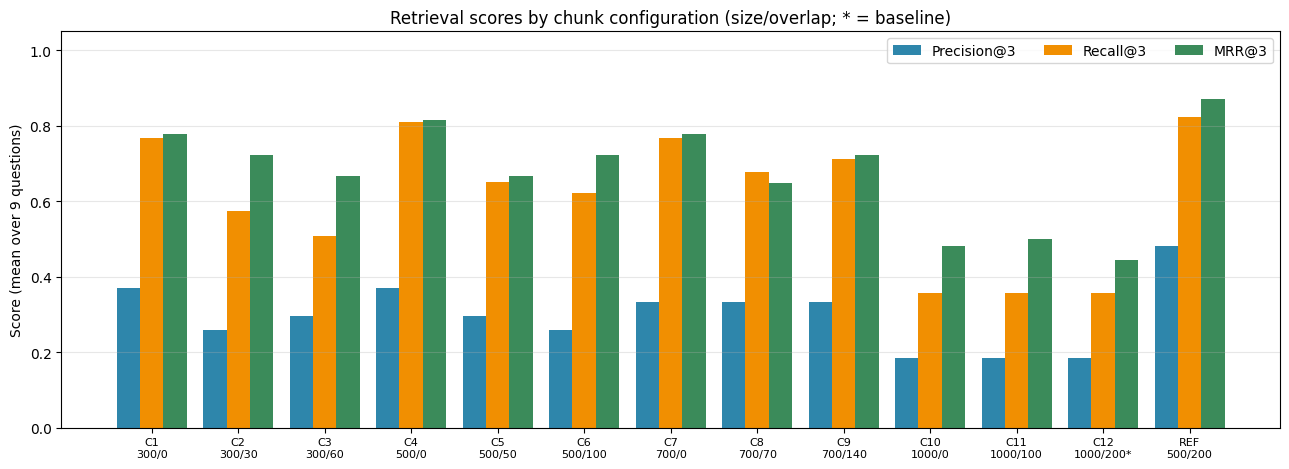

In [22]:
labels = [f"{r.Config}\n{r.Chunk_Size}/{r.Overlap}" + ("*" if (r.Chunk_Size, r.Overlap) == BASELINE else "")
          for r in table_a.itertuples()]
x = np.arange(len(table_a))
w = 0.27

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.bar(x - w, table_a["Precision@3"], w, label="Precision@3", color="#2E86AB")
ax.bar(x,     table_a["Recall@3"],    w, label="Recall@3",    color="#F18F01")
ax.bar(x + w, table_a["MRR@3"],       w, label="MRR@3",       color="#3B8B5A")
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score (mean over 9 questions)")
ax.set_title("Retrieval scores by chunk configuration (size/overlap; * = baseline)")
ax.legend(ncol=3, loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("pt_f2_metrics_chart.png", dpi=200)
plt.show()

## E7. Chart 2 — Quality vs. cost

**What this cell does.** It draws a second chart for the report's discussion of *"trade-offs between retrieval quality and efficiency"* (Step 9D). It shows quality and cost in one picture.

**Step by step**
1. `ax.scatter(...)` draws one dot per setting:
   - **left to right:** the total number of chunks (the cost);
   - **bottom to top:** the mean Recall@3 (how much of the evidence was found);
   - **dot size:** the MRR@3. `s=60 + 340 * MRR@3` makes the dot bigger when the evidence is found earlier. The 60 keeps even an MRR of 0 visible.
2. The `for` loop with `ax.annotate(...)` writes each setting's name and size/overlap next to its dot. `xytext=(6, 5)` moves the label a little up and right so it does not cover the dot.
3. Axis labels, a title, and a light grid are added.
4. The chart is saved as `pt_f2_quality_vs_cost.png` and shown.

**How to read it.**
- The **best** settings are near the **top left**: they find a lot of evidence with few chunks.
- A setting at the **top right** finds a lot of evidence, but at a high cost.
- If two dots are at **about the same height** but **far apart** left to right, they found about the same amount of evidence with very different numbers of chunks. That is exactly what Step 7 question 10 asks about.

**What I will check.** The chart is saved, and every one of the 13 dots has a label.

**What I saw in my run.**
- **Top left:** the best value for the cost is **C7 (700/0)**: 296 chunks with Recall@3 0.767. **C4 (500/0)** is close: 400 chunks with Recall@3 0.811.
- **Same cost, different quality:** C1 (300/0) and REF (500/200) sit at the same place on the left-right axis (640 chunks each, because both have a step of 300). But REF is higher (0.822 vs. 0.769) and has a bigger dot (MRR@3 0.870 vs. 0.778).
- **Bottom left:** C10, C11, and C12 (1000 characters) are cheap but find little evidence.
- **Bottom right:** C2 and C3 (300 characters with overlap) are the most expensive and also among the weakest. More chunks did **not** mean better results.

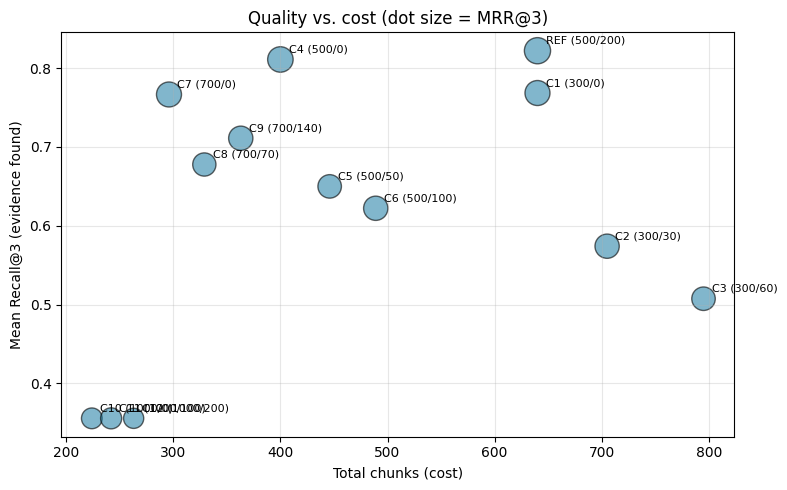

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(table_a["Total_Chunks"], table_a["Recall@3"], s=60 + 340 * table_a["MRR@3"],
           alpha=0.6, color="#2E86AB", edgecolor="black")
for cfg_id, size, ov, n_chunks, rec in zip(table_a["Config"], table_a["Chunk_Size"], table_a["Overlap"],
                                           table_a["Total_Chunks"], table_a["Recall@3"]):
    ax.annotate(f"{cfg_id} ({size}/{ov})", (n_chunks, rec),
                textcoords="offset points", xytext=(6, 5), fontsize=8)
ax.set_xlabel("Total chunks (cost)")
ax.set_ylabel("Mean Recall@3 (evidence found)")
ax.set_title("Quality vs. cost (dot size = MRR@3)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pt_f2_quality_vs_cost.png", dpi=200)
plt.show()

## E8. Saving everything to Excel

**What this cell does.** It saves the **excel log file** that Step 6 asks for, **`pt_f2_experiment_log.xlsx`**, with *"the following tables in separate worksheets"*. It also downloads the Excel file and both charts. These are submission items 2 and 3 (*"the experiment results spreadsheet"* and *"the detailed retrieval log"*).

| Sheet | What it has | Activity link |
|---|---|---|
| **Table_A_Config_Results** | One row per setting: chunks, Precision@3, Recall@3, MRR@3, questions with all evidence | Table A |
| **Table_B_By_Difficulty** | Three rows per setting: easy, average, difficult | Table B |
| **Table_C_Retrieval_Log** | Every retrieved chunk (351 rows) with all the required columns | Table C |
| **Baseline_C12_Log** | Only the baseline's Table C rows | Step 1: *"Save the retrieved chunks, their ranks, their source references, and the evaluation results"* of the baseline |
| **Per_Question_Scores** | Every setting × question, with its three scores | Supports Tables A and B |
| **Efficiency** | Chunks, tokens, indexing time, index size, search times | Step 8 efficiency |
| **Implementation_Checks** | The Step 3 checks for every setting | Step 3 required checks |
| **Ground_Truth** | The 9 questions, answers, units, pages, and anchor phrases | Submission item 5: *"verified test-question evidence"* |

**Step by step**
1. `ground_truth_df` makes one row per evidence unit (21 rows), with the question, its answer, the unit ID and description, the page, and the anchor phrases joined with ` | `.
2. `baseline_label` finds the label of the baseline setting (`C12 (1000/200)`), so its rows can be filtered out of Table C.
3. `sheets` is a dictionary from sheet name to table. Scores are rounded to 4 decimals.
4. `pd.ExcelWriter(LOG_FILE, engine="openpyxl")` opens a new Excel file. The `with` block makes sure it is saved and closed properly at the end.
5. For each sheet:
   - `df.to_excel(...)` writes the table, without pandas' row numbers;
   - the header row gets **bold white text on a dark blue background**;
   - `freeze_panes = "A2"` keeps the header visible while scrolling;
   - column widths are set: **70** for long text columns (chunk text, anchors, answers, questions), and wide enough for the header name for the others.
6. The number of rows in each sheet is printed as a check.
7. `files.download(...)` sends the Excel file and both chart images to my computer.

**What I will check.** Three files download. The sheets should have these row counts: Table A **13**, Table B **39**, Table C **351**, Baseline **27**, Per-question **117**, Efficiency **13**, Checks **13**, Ground truth **21**.

**What I saw in my run.** `Saved: pt_f2_experiment_log.xlsx` with the expected row counts: Table A 13, Table B 39, Table C 351, Baseline log 27, Per-question 117, Efficiency 13, Checks 13, Ground truth 21. The Excel file and both charts downloaded.

In [24]:
ground_truth_df = pd.DataFrame([
    {"Question_ID": q["id"], "Difficulty": q["difficulty"], "Question": q["question"],
     "Expected_Answer": q["expected_answer"], "Unit_ID": u["unit"], "Unit_Description": u["desc"],
     "Page": u["page"], "Anchor_Phrases": " | ".join(u["anchors"])}
    for q in TEST_QUESTIONS for u in q["units"]
])

baseline_label = next(f"{c['config']} ({c['chunk_size']}/{c['overlap']})" for c in CONFIGS
                      if (c["chunk_size"], c["overlap"]) == BASELINE)

LOG_FILE = "pt_f2_experiment_log.xlsx"
sheets = {
    "Table_A_Config_Results": table_a.round(4),
    "Table_B_By_Difficulty": table_b.round(4),
    "Table_C_Retrieval_Log": log_df,
    "Baseline_C12_Log": log_df[log_df["Configuration"] == baseline_label],
    "Per_Question_Scores": question_df.round(4),
    "Efficiency": efficiency_df,
    "Implementation_Checks": checks_df,
    "Ground_Truth": ground_truth_df,
}

with pd.ExcelWriter(LOG_FILE, engine="openpyxl") as writer:
    for name, df in sheets.items():
        df.to_excel(writer, sheet_name=name, index=False)
        ws = writer.sheets[name]
        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill(fill_type="solid", fgColor="1F4E78")
        ws.freeze_panes = "A2"
        for col in ws.columns:
            letter = col[0].column_letter
            header = str(col[0].value)
            ws.column_dimensions[letter].width = 70 if header in ("Chunk_Text", "Anchor_Phrases", "Expected_Answer", "Question") else max(12, len(header) + 2)

print("Saved:", LOG_FILE)
for name, df in sheets.items():
    print(f"  {name:24s} {len(df):4d} rows")

for f in [LOG_FILE, "pt_f2_metrics_chart.png", "pt_f2_quality_vs_cost.png"]:
    files.download(f)

Saved: pt_f2_experiment_log.xlsx
  Table_A_Config_Results     13 rows
  Table_B_By_Difficulty      39 rows
  Table_C_Retrieval_Log     351 rows
  Baseline_C12_Log           27 rows
  Per_Question_Scores       117 rows
  Efficiency                 13 rows
  Implementation_Checks      13 rows
  Ground_Truth               21 rows


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part F — Analysis

## F1. Answers to the 10 analysis questions (from the numbers)

**What this cell does.** Step 7 of the activity asks 10 analysis questions, and says to *"support each major conclusion with numerical results"*. This cell computes the answer to each question **directly from the result tables**, so my analysis is based on the numbers and not on my impression of the charts. In the IEEE report, I explain these answers in words and add examples from Table C.

**Important:** only the **12 required settings** (C1 to C12) are compared here. The REF setting is left out (`main = A.drop(index="REF")`), because it is not part of the required grid.

**How each question is answered**

| # | Activity's question | How the code answers it |
|---|---|---|
| 1 | Which configuration achieved the highest Precision@3? | The setting(s) with the highest mean Precision@3. If several tie, all are listed. |
| 2 | Which configuration achieved the highest Recall@3? | The same, for Recall@3. |
| 3 | Which configuration achieved the highest MRR@3? | The same, for MRR@3. |
| 4 | Did the configuration with the highest score on one metric also perform well on the other metrics? | For each winner of questions 1–3, all three of its scores are printed side by side. |
| 5 | Which chunk size performed best when comparing configurations with the same overlap percentage? | For each overlap percentage (0%, 10%, 20%), the four sizes are ranked by the average of their three scores (`Mean_of_3`). |
| 6 | How did increasing overlap affect retrieval quality and the total number of chunks? | For each size, the chunk count, Recall@3, and MRR@3 are shown going from 0% → 10% → 20% overlap. |
| 7 | Which configuration performed best on difficult questions? | The difficult rows of Table B are ranked by Recall@3 (completeness), then MRR@3, then Precision@3. The top 3 are shown. |
| 8 | Did smaller chunks improve the ranking of focused evidence, or did they fragment information? | The 300-character settings are averaged and compared with the 500–700 and 1000 settings, on Precision@3 (focus) and on questions with all evidence (completeness). |
| 9 | Did larger chunks preserve useful context, or did they introduce irrelevant information? | The same comparison, looking at the 1000-character group. |
| 10 | Were there configurations with similar retrieval quality but very different numbers of chunks? | Every pair of settings is compared. A pair is printed if all three scores are within 0.05 **and** the chunk counts differ by 30% or more. |

**Step by step: helper code**
1. `A = table_a.set_index("Config")` makes Table A easy to look up by setting name.
2. `main["Mean_of_3"]` is the simple average of the three scores. It is used only for question 5, to rank sizes with one number.
3. `best(col)` finds the highest value of a column and returns **all** settings that have it. `np.isclose` is used instead of `==`, so tiny rounding differences do not hide a tie.
4. `scores(c)` returns a short text with a setting's three scores.
5. `group_summary(...)` averages a group of settings, for questions 8 and 9.

**What I will check.** Ten clear answers are printed. I copy them into my report and explain each one.

**What I saw in my run (the answers to the 10 questions)**

| # | Answer from my results |
|---|---|
| 1 | **Highest Precision@3:** C1 (300/0) and C4 (500/0), tied at 0.370. |
| 2 | **Highest Recall@3:** C4 (500/0), 0.811. |
| 3 | **Highest MRR@3:** C4 (500/0), 0.815. |
| 4 | **Yes.** C4 is the top setting on all three scores. C1 ties on precision but is lower on recall (0.769) and MRR (0.778). |
| 5 | At **0% overlap**: 500 (0.665) > 300 (0.639) > 700 (0.626) > 1000 (0.341). At **10%** and **20%**: 700 is first and 500 is second. **1000 is last at every overlap level.** |
| 6 | More overlap **always made more chunks** (+8% to +24%), but it **did not improve the scores**. For 300 characters, Recall@3 went 0.77 → 0.57 → 0.51. For 500: 0.81 → 0.65 → 0.62. For 700: 0.77 → 0.68 → 0.71. For 1000, it did not change (0.36). |
| 7 | **Best on difficult questions:** C1 (300/0), with Recall@3 0.833 and MRR@3 0.833, then C9 (700/140) with Recall@3 0.667. |
| 8 | **Small chunks:** they ranked focused evidence well (C1 tied for best precision, and was best on difficult questions). But sometimes they separated an article's heading from its list. For example, in A2 the 300/30 chunk at rank 1 was the opening of Article 101, without the remedies. |
| 9 | **Large chunks:** the 1000-character chunks mostly added unrelated text. They had the lowest precision (0.185) at every overlap, and they missed the easy questions E1 and E3. |
| 10 | **Yes.** C1 (640 chunks), C4 (400), and C7 (296) are all within 0.05 of each other on all three scores. C7 needs less than half the chunks of C1. |

In [25]:
A = table_a.set_index("Config")
B = table_b
main = A.drop(index="REF")            # the 12 required settings
main["Mean_of_3"] = main[["Precision@3", "Recall@3", "MRR@3"]].mean(axis=1)

def best(col, df=main):
    top = df[col].max()
    return ", ".join(f"{c} ({int(df.loc[c,'Chunk_Size'])}/{int(df.loc[c,'Overlap'])})"
                     for c in df.index[np.isclose(df[col], top)]), top

def scores(c):
    r = A.loc[c]
    return f"P@3={r['Precision@3']:.3f}, R@3={r['Recall@3']:.3f}, MRR@3={r['MRR@3']:.3f}"

for qn, col in [("Q1", "Precision@3"), ("Q2", "Recall@3"), ("Q3", "MRR@3")]:
    who, val = best(col)
    print(f"{qn}. Highest {col:11s}: {who}  = {val:.3f}")

print("\nQ4. Do the winners also do well on the other scores?")
for col in ["Precision@3", "Recall@3", "MRR@3"]:
    for c in main.index[np.isclose(main[col], main[col].max())]:
        print(f"    best {col:11s} -> {c}: {scores(c)}")

print("\nQ5. Best chunk size at the same overlap % (mean of the 3 scores):")
pct = {c["config"]: c["overlap_pct"] for c in CONFIGS}
main["Overlap_%"] = [pct[c] for c in main.index]
for p_ in sorted(main["Overlap_%"].unique()):
    sub = main[main["Overlap_%"] == p_].sort_values("Mean_of_3", ascending=False)
    print(f"    {p_:2d}% overlap: " + " > ".join(f"{int(r.Chunk_Size)} ({r.Mean_of_3:.3f})" for r in sub.itertuples()))

print("\nQ6. Effect of increasing overlap (0% -> 10% -> 20%):")
for size in CHUNK_SIZES:
    sub = main[main["Chunk_Size"] == size].sort_values("Overlap_%")
    print(f"    size {size:4d}: chunks " + " -> ".join(str(int(v)) for v in sub["Total_Chunks"])
          + " | R@3 " + " -> ".join(f"{v:.2f}" for v in sub["Recall@3"])
          + " | MRR@3 " + " -> ".join(f"{v:.2f}" for v in sub["MRR@3"]))

d = B[(B["Difficulty"] == "Difficult") & (B["Config"] != "REF")].set_index("Config")
d_top = d.sort_values(["Recall@3", "MRR@3", "Precision@3"], ascending=False)
print("\nQ7. Best on difficult questions:")
print(d_top[["Chunk_Size", "Overlap", "Precision@3", "Recall@3", "MRR@3"]].head(3).round(3).to_string())

def group_summary(mask, name):
    g = main[mask]
    return (f"{name}: mean P@3={g['Precision@3'].mean():.3f}, R@3={g['Recall@3'].mean():.3f}, "
            f"MRR@3={g['MRR@3'].mean():.3f}, questions with all evidence (avg)={g['Questions_With_All_Evidence'].mean():.1f}/9")

print("\nQ8/Q9. Small vs. medium vs. large chunks:")
print("    " + group_summary(main["Chunk_Size"] == 300, "300 chars "))
print("    " + group_summary(main["Chunk_Size"].isin([500, 700]), "500-700   "))
print("    " + group_summary(main["Chunk_Size"] == 1000, "1000 chars"))

print("\nQ10. Similar quality but very different chunk counts (all 3 scores within 0.05, chunks differ >= 30%):")
found = False
idx = list(main.index)
for i in range(len(idx)):
    for j in range(i + 1, len(idx)):
        a, b = main.loc[idx[i]], main.loc[idx[j]]
        close = all(abs(a[m] - b[m]) <= 0.05 for m in ["Precision@3", "Recall@3", "MRR@3"])
        ratio = max(a["Total_Chunks"], b["Total_Chunks"]) / min(a["Total_Chunks"], b["Total_Chunks"])
        if close and ratio >= 1.3:
            found = True
            print(f"    {idx[i]} ({int(a['Total_Chunks'])} chunks) vs {idx[j]} ({int(b['Total_Chunks'])} chunks): "
                  f"{scores(idx[i])}  |  {scores(idx[j])}")
if not found:
    print("    None found.")

Q1. Highest Precision@3: C1 (300/0), C4 (500/0)  = 0.370
Q2. Highest Recall@3   : C4 (500/0)  = 0.811
Q3. Highest MRR@3      : C4 (500/0)  = 0.815

Q4. Do the winners also do well on the other scores?
    best Precision@3 -> C1: P@3=0.370, R@3=0.769, MRR@3=0.778
    best Precision@3 -> C4: P@3=0.370, R@3=0.811, MRR@3=0.815
    best Recall@3    -> C4: P@3=0.370, R@3=0.811, MRR@3=0.815
    best MRR@3       -> C4: P@3=0.370, R@3=0.811, MRR@3=0.815

Q5. Best chunk size at the same overlap % (mean of the 3 scores):
     0% overlap: 500 (0.665) > 300 (0.639) > 700 (0.626) > 1000 (0.341)
    10% overlap: 700 (0.553) > 500 (0.538) > 300 (0.519) > 1000 (0.347)
    20% overlap: 700 (0.589) > 500 (0.535) > 300 (0.490) > 1000 (0.328)

Q6. Effect of increasing overlap (0% -> 10% -> 20%):
    size  300: chunks 640 -> 705 -> 795 | R@3 0.77 -> 0.57 -> 0.51 | MRR@3 0.78 -> 0.72 -> 0.67
    size  500: chunks 400 -> 446 -> 489 | R@3 0.81 -> 0.65 -> 0.62 | MRR@3 0.81 -> 0.67 -> 0.72
    size  700: chunks 

## F2. Finding the recommended setting

**What this cell does.** Step 8 of the activity explains how to choose the best setting. It says: *"Do not automatically select the configuration with the highest value for a single metric."* It also lists five things to consider: retrieval quality, question difficulty, evidence completeness, efficiency, and consistency. This cell applies those rules step by step, and prints the result **and** the reasons. I still read all the tables myself before I write the final recommendation in my report.

**The rules, in order**
1. **Evidence completeness first.** The settings are sorted by mean **Recall@3**, then by **Questions_With_All_Evidence**. A setting that leaves evidence out cannot support a complete, grounded answer, so this comes first.
2. **Ranking quality and focus next.** Ties are broken by **MRR@3** (evidence found earlier), then **Precision@3** (less useless text).
3. **Comparable settings.** A setting counts as *comparable* to the top one if:
   - its Recall@3 and MRR@3 are both within **0.05** of the top setting's,
   - its Precision@3 is within **0.10**,
   - and it finds all the evidence for **at least as many** questions.

   This follows Step 8: *"If two or more configurations have comparable retrieval performance, prefer the configuration that offers a practical efficiency advantage, provided that it does not materially reduce evidence coverage."* I allow a bigger gap for Precision@3 because, with only 3 results, one extra useless chunk changes Precision@3 by 0.11 for one question.
4. **Efficiency.** Among the comparable settings, the one with the **fewest chunks** is chosen.
5. **Consistency.** For the chosen setting, the cell lists the questions with **RR = 0** (no useful chunk at all in the top 3). Fewer such questions means the setting works across all questions, not just a few. Step 8 asks for this: *"performs well across the test questions rather than excelling on only one or two questions."*
6. **Is there a clear winner?** If the top two settings are within **0.01** on all three scores, the cell prints a note saying that the experiment does not show a clear winner between them. Step 8 asks me to state this honestly: *"If your results are tied or nearly identical, state that the experiment does not establish a clear winner."*

**Step by step: the code**
1. `rank_df` is the 12 settings sorted by rules 1 and 2. It is printed in full, so the whole ranking can be seen, not just the winner.
2. `top` is the first row.
3. `comparable` keeps the settings that pass rule 3. The top setting always passes, since it is compared with itself.
4. `chosen_id` is the comparable setting with the fewest chunks (rule 4).
5. `zero_rr` lists the chosen setting's questions with RR = 0 (rule 5).
6. The rule 6 check compares the top two settings.
7. Finally, the scores of the **REF** setting (Part 1's best, 500/200) and the **baseline** (C12, 1000/200) are printed, so I can compare the recommendation with both in my report.

**What I will check.** The printed ranking, the list of comparable settings, the chosen setting with its size and overlap, its RR = 0 questions, and the REF and baseline scores.

**What I saw in my run.**
- **Top by scores:** C4 (500/0, 400 chunks).
- **Comparable settings:** C4, C1, and C7.
- **Chosen by the automatic rule:** C7 (700/0), because it has the fewest chunks (296) among the comparable settings.
- **Questions with RR = 0 in C7:** D3.
- REF scored P@3 0.481, R@3 0.822, MRR@3 0.870. The baseline scored 0.185, 0.356, and 0.444.
- No "no clear winner" note was printed.

**Why I did not accept the automatic choice.** The automatic rule only looks at averages and chunk counts. When I read the per-question results, I saw that C7 found **no evidence at all** for the difficult question D3 (Recall@3 = 0 and RR = 0). Step 8 says the recommendation must consider **consistency**, *"whether the configuration performs well across the test questions rather than excelling on only one or two"*, and **evidence completeness**. So C7 is not my recommendation. This is exactly why the activity says *"Do not automatically select"*, and why I read the tables myself.

**My final recommendation: chunk size 500, overlap 200.**
1. **Chunk size 500** is supported twice. It is the size of the best grid setting (C4, 500/0) **and** of the best overall setting (REF, 500/200). It also ranked first or second at every overlap level.
2. **500/200 vs. 500/0.** REF is higher on all three scores (P@3 0.481 vs. 0.370, R@3 0.822 vs. 0.811, MRR@3 0.870 vs. 0.815). It finds all the evidence for more questions (6 vs. 5 of 9), and it is better on difficult questions (Recall@3 0.67 vs. 0.50). Neither has any question with RR = 0.
3. **Cost.** REF needs 640 chunks instead of 400 (960 KB instead of 600 KB, and about 0.07 ms more per search). For an 81-page document, this is a very small cost.
4. **Not "comparable".** The differences in precision (0.11) and MRR (0.055) are bigger than my "comparable" limits, so the efficiency rule does not favor 500/0 here.
5. **It also won in Part 1**, with different questions, which makes the result more trustworthy.

If a smaller index is needed, **500/0 (C4)** is my alternative: it is the best and most consistent of the 12 grid settings. The 1000/200 baseline should not be used for RA 7394.

In [26]:
rank_df = main.sort_values(["Recall@3", "Questions_With_All_Evidence", "MRR@3", "Precision@3"],
                           ascending=False).copy()
print("Ranking (completeness first, then MRR@3, then Precision@3):")
print(rank_df[["Chunk_Size", "Overlap", "Total_Chunks", "Precision@3", "Recall@3", "MRR@3",
               "Questions_With_All_Evidence"]].round(3).to_string())

top = rank_df.iloc[0]
comparable = rank_df[(rank_df["Recall@3"] >= top["Recall@3"] - 0.05)
                     & (rank_df["MRR@3"] >= top["MRR@3"] - 0.05)
                     & (rank_df["Precision@3"] >= top["Precision@3"] - 0.10)
                     & (rank_df["Questions_With_All_Evidence"] >= top["Questions_With_All_Evidence"])]
chosen_id = comparable.sort_values("Total_Chunks").index[0]
chosen = main.loc[chosen_id]

print("\nTop by scores      :", rank_df.index[0], f"({int(top['Chunk_Size'])}/{int(top['Overlap'])}, {int(top['Total_Chunks'])} chunks)")
print("Comparable settings:", ", ".join(f"{c} ({int(main.loc[c,'Total_Chunks'])} chunks)" for c in comparable.index))
print("Chosen (fewest chunks among comparable):", chosen_id,
      f"-> chunk size {int(chosen['Chunk_Size'])}, overlap {int(chosen['Overlap'])}")

zero_rr = question_df[(question_df["Config"] == chosen_id) & (question_df["RR"] == 0)]["Question_ID"].tolist()
print("Questions with no useful chunk (RR = 0) in the chosen setting:", zero_rr if zero_rr else "none")

second = rank_df.iloc[1]
if all(abs(top[m] - second[m]) <= 0.01 for m in ["Precision@3", "Recall@3", "MRR@3"]):
    print("\nNOTE: the top two settings are within 0.01 on all three scores, so the experiment "
          "does not show a clear winner between them.")

print("\nReference (Part 1 best, 500/200):", scores("REF"))
print("Baseline  (C12, 1000/200)       :", scores("C12"))

Ranking (completeness first, then MRR@3, then Precision@3):
        Chunk_Size  Overlap  Total_Chunks  Precision@3  Recall@3  MRR@3  Questions_With_All_Evidence
Config                                                                                              
C4             500        0           400        0.370     0.811  0.815                            5
C1             300        0           640        0.370     0.769  0.778                            5
C7             700        0           296        0.333     0.767  0.778                            6
C9             700      140           363        0.333     0.711  0.722                            6
C8             700       70           329        0.333     0.678  0.648                            5
C5             500       50           446        0.296     0.650  0.667                            3
C6             500      100           489        0.259     0.622  0.722                            4
C2             300       30    

# Part G — Summary of My Results

## The main results

| | P@3 | R@3 | MRR@3 | All evidence | Chunks |
|---|---|---|---|---|---|
| **REF 500/200 (recommended)** | **0.481** | **0.822** | **0.870** | 6/9 | 640 |
| C4 500/0 (best of the 12 grid settings) | 0.370 | 0.811 | 0.815 | 5/9 | 400 |
| C12 1000/200 (class baseline) | 0.185 | 0.356 | 0.444 | 2/9 | 263 |

## What I learned

1. **Chunk size mattered much more than overlap.** The 1000-character settings found only about a third of the evidence (Recall@3 0.356) at every overlap. The 500- and 700-character settings found 62% to 81%. The reason is that RA 7394 is made of many short articles. In a 1,000-character chunk, a one-sentence article like Article 66 is **buried** in other text, so the chunk's vector is mostly about the other text. In my run, none of the 1000-character chunks went over the 256-token embedding limit, so the cut-off was not the cause.
2. **Overlap did not help in my grid.** More overlap always made more chunks, but the scores usually went down. Overlap does not add new information. It only moves where the chunk edges fall. With only 9 questions, an edge moving a few characters can decide whether one chunk holds a whole answer. REF (40% overlap) was still the best overall, so overlap is not bad in itself. Its effect on this document depended on **where** the edges fell, not on **how much** text was repeated.
3. **Small chunks can separate a heading from its content.** With 300-character chunks, the search sometimes found the right article's opening (for example, Article 101 for A2, or Article 2 for A3), while the actual list of remedies or objectives was in the next chunk.
4. **Answers split across pages or articles are still hard.** No setting found all 5 objectives of Article 2 (A3), because they cross from page 1 to page 2. Most settings found only one of the two articles for the difficult questions. One search with top 3 is not enough for these. In Part 1, splitting comparison questions into two searches helped, and that would be a good next step here.
5. **A high similarity score is not the same as relevance** (Lecture 8). The baseline returned chunks with scores around 0.58 to 0.60 for E1, and none of them answered the question.

## Final recommendation

**Chunk size 500, overlap 200** for RA 7394, with **500/0** as the alternative if a smaller index is needed. The full discussion is in my IEEE report.